# Gaussian processes as PyMC models: a tour

This notebook is a walk through one design for a GP library, on its own terms. It has two layers, and the whole tour
is about keeping them apart:

1. **The model says what the model is.** A GP model is an ordinary PyMC model. A GP is a named process `f`, and
   `f(X)` is its values at the inputs `X`, a random variable. Likelihoods are ordinary PyMC distributions. Nothing in
   the model says how it will be fitted.
2. **The objective says how the model is fitted.** `objective(model, approx)` reads the model graph and builds a fitting
   criterion from it: an exact marginal likelihood, a sparse bound, or an evidence lower bound (ELBO). `approx` is a
   dictionary that names, for each variable, how it's handled. The result is a set of **named terms**, the way
   `model.logp(sum=False)` gives one term per variable.

Prediction comes in two kinds, and they're handled differently:

- **the GP's value at new inputs** ("what does $f$ look like here?") is asked of the fitted objective,
  `fit.predict("f", X_new)`, and doesn't touch the model;
- **a new observation** ("what will the next measurement be?") is a statement about the world, so it's written in the
  model, next to the observed data, as a variable like `y_pred`.

Because the model is just PyMC, PyMC's own tools work on it: `pm.set_data` moves where new observations are
predicted, `pm.do` fixes variables, `pm.observe` turns a variable into data, and `pm.Minibatch` streams training data.

The code is a prototype package in this directory, `gp_as_pymc_model` (imported as `gpm`), so run the notebook from
here. It builds on kernels as graphs of typed `KernelOp`s (#76).

**Contents**

1. A GP model in PyMC
2. How it's built: the architecture and the code
3. Fitting it: the objective and its terms
4. Prediction: the GP, and new observations
5. One model, four approximations
6. Changing the model with PyMC
7. Training on minibatches
8. Other likelihoods
9. One GP, seen through two likelihoods
10. More than one GP: a GP for the noise
11. Putting it together: predicting water-main breaks
12. Additive GPs: a sum of GPs, fitted as one GP
13. What typed nodes buy: GPs, kernels and likelihoods as Ops
14. Correlated outputs
15. Optimizers: parameter groups and natural gradients
16. Summary

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import scipy.stats as st
from pytensor.graph.traversal import ancestors

from pytensor_ml.optim import adam, sgd

import gp_as_pymc_model as gpm
import ptgp as pg

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (9, 3.2), "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(1)
N = 80
X_np = np.sort(rng.uniform(-2, 2, N))[:, None]
y_np = np.sin(2 * X_np[:, 0]) + 0.2 * rng.standard_normal(N)
grid = np.linspace(-2.6, 2.6, 200)[:, None]  # where we'll look at f


def band(ax, x, mean, var, label=None, color="C0"):
    sd = np.sqrt(var)
    ax.plot(x, mean, color=color, label=label)
    ax.fill_between(x, mean - 2 * sd, mean + 2 * sd, color=color, alpha=0.2, lw=0)

## 1. A GP model in PyMC

A GP is a distribution over functions, so it's infinite-dimensional. We only ever deal with it at finitely many
inputs, and they're all values of **one** function.

That's what the syntax says. `f = gpm.GP("f", kernel)` is the process itself; it isn't a variable yet. `f(X)` is its
values at the rows of `X`, a random variable. Evaluating it somewhere else, `f(X_new)`, gives the same function's
values there; together the evaluations are one draw of the GP. Calling `f` again with the same inputs gives back the
same variable.

A GP regression model has:

- **hyperparameters** with priors: a lengthscale `ls`, an amplitude `eta`, a noise scale `sigma`;
- **the GP** `f`, with a kernel built from them;
- a **likelihood** for the data, `pm.Normal("y", mu=f(X), sigma=sigma, observed=y)`. It's an ordinary PyMC
  distribution, and any other one works the same way (section 8);
- **a new observation** at inputs `X_new`: `pm.Normal("y_new", mu=f(X_new), sigma=sigma)`. It's written the same way
  as `y`, because a new measurement is generated the same way as the old ones. It just has no `observed=` data.

Nothing declares which part of the GP is observed: `f(X)` feeds a likelihood with data, so it's observed, and `f(X_new)`
doesn't. `X_new` is a `pm.Data`, so where new observations are predicted can be changed later.

In [2]:
def gp_regression():
    with pm.Model() as m:
        X = pm.Data("X", X_np)
        X_new = pm.Data("X_new", np.array([[-2.4], [0.0], [2.4]]))

        ls = pm.InverseGamma("ls", 3.0, 1.0)
        eta = pm.Exponential("eta", scale=1.0)
        sigma = pm.HalfNormal("sigma", 1.0)

        f = gpm.GP("f", eta**2 * pg.kernels.ExpQuad(input_dim=1, ls=ls))

        pm.Normal("y", mu=f(X), sigma=sigma, observed=y_np)
        pm.Normal("y_new", mu=f(X_new), sigma=sigma)
    return m


m = gp_regression()
print("free variables:    ", [v.name for v in m.free_RVs])
print("observed variables:", [v.name for v in m.observed_RVs])
print("potentials:        ", m.potentials)

free variables:     ['ls', 'eta', 'sigma', 'f(X)', 'f(X_new)', 'y_new']
observed variables: ['y']
potentials:         []


The GP's evaluations are named after their inputs, `f(X)` and `f(X_new)`. There are no potentials and no special
objects: this is a model you could hand to any PyMC tool. (Under the hood, the first evaluation is drawn from the GP
prior and each later one from the GP conditional given the earlier ones, which is how a joint Gaussian factors. That's
an implementation detail; the order of the calls doesn't change the model.)

Drawing from its prior shows what it says before seeing data. Each line is one draw of the GP, at the training inputs:

Sampling: [eta, f(X), ls, sigma, y]


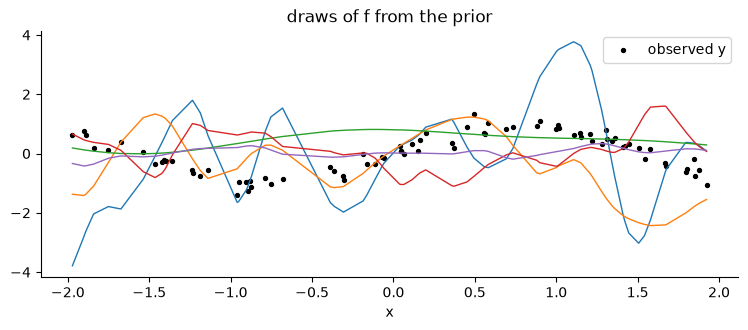

In [3]:
prior = pm.sample_prior_predictive(draws=5, model=m, var_names=["f(X)", "y"], random_seed=1)
fig, ax = plt.subplots()
for k in range(5):
    ax.plot(X_np[:, 0], prior.prior["f(X)"].values[0, k], lw=1)
ax.scatter(X_np[:, 0], y_np, s=8, color="k", label="observed y")
ax.set(title="draws of f from the prior", xlabel="x")
ax.legend();

## 2. How it's built: the architecture and the code

Before fitting anything, here is how the pieces fit together. There are three layers, and each only reads the one
before it:

```
  MODEL (PyMC)                     OBJECTIVE                          FIT
  -----------------------------    -------------------------------    ------------------------------
  pm.Model                         gpm.objective(model, approx)       gpm.fit / compile_training_step
    hyperparameters (RVs)   --->     asks each family for its   --->    give a Fit:
    f = gpm.GP("f", kernel)          terms, returns an Objective:       estimates, trace, history,
    f(X), f(X_new) (RVs)               terms, pointwise, params,        diagnostics
    likelihoods (PyMC dists)           inputs, diagnostics,             fit.predict("f", X)
    y_new (no observed=)               bound, loss                      fit.predict_new("y_new")
```

The model never refers to the objective, and the objective never changes the model. All the GP mathematics (kernels,
conditionals, the KL of $q(u)$, the exact, VFE and FITC objectives, the diagnostics) is ptgp's existing code; this
design changes who calls it and with what.

The package has five modules:

| Module | What's in it |
|---|---|
| `model.py` | `GP`, the `GPRV` Op that each evaluation is, and `processes(model)`, which finds the GPs in a model |
| `families.py` | One class per way of handling a variable: `Exact`, `VFE`, `FITC`, `SVGP` for GPs; `MeanField`, `Gaussian`, `Point` for the rest. **Each family builds its own terms**, so a new approximation is a new class |
| `expectations.py` | Expected log-likelihoods: closed forms, the linear-predictor search, quadrature |
| `objective.py` | `objective(model, approx)` and the `Objective` it returns |
| `fit.py` | `fit` (scipy), `compile_training_step` (pytensor-ml optimizers, per parameter group), `natural_gradient`, and the `Fit` object, which holds the training history and predicts |

### 2.1 The model layer: a GP is one Op

Kernels are typed nodes in the graph (`KernelOp`), and likelihoods are PyMC random-variable Ops. A GP evaluation is
the same kind of thing: **one node, of type `GPRV`**.

`f = gpm.GP("f", kernel, mean)` stores the kernel and mean, and works out the GP's **parameters**: the variables its
kernel and mean are built from that aren't the inputs `X` (here `ls` and the amplitude `eta**2`). Calling it creates a
node:

- the **first** call, `f(X)`, is `GPRV(rng, X, *parameters)`: the GP prior at `X`;
- each **later** call, `f(X_new)`, is `GPRV(rng, X_new, given_rows, given_values, *parameters)`: the GP conditional
  given all earlier evaluations. Together they're the joint distribution of the GP at all the inputs;
- calling it again with the same inputs returns the existing variable.

Inside, the node draws from a multivariate normal, so PyMC can sample it and derive its log density with no extra
code. What makes it more than an `MvNormal` is what the Op knows: which process it belongs to, which inputs are the
rows, and the process's kernel and mean **as functions of its parameter inputs**.

In [4]:
node = m["f(X_new)"].owner
print("f(X_new) is a", type(node.op).__name__, "node of process", repr(node.op.process), "| evaluation", node.op.index)
label = lambda v: v.name or "an expression of " + ", ".join(a.name for a in ancestors([v]) if a in m.free_RVs)
print("its inputs: ", ["rng"] + [label(i) for i in node.inputs[1:]])

fixed = pm.do(m, {"ls": 0.5, "eta": 1.0, "sigma": 0.2})
for proc in gpm.processes(fixed):
    print(f"\nafter pm.do, processes() finds GP {proc.name!r}: observed {[rv.name for rv, _ in proc.observed]}, "
          f"not observed {[rv.name for rv, _ in proc.predictive]}")

f(X_new) is a GPRV node of process 'f' | evaluation 1
its inputs:  ['rng', 'X_new', 'X', 'f(X)', 'ls', 'an expression of eta']

after pm.do, processes() finds GP 'f': observed ['f(X)'], not observed ['f(X_new)']


`processes(model)` collects the `GPRV` nodes of each process and sorts them into **observed** (a likelihood with data
reads them directly) and **not observed** (everything else, such as `f(X_new)`).

**The kernel comes from the node, at its current inputs.** After `pm.do(ls=0.5, eta=1.0)`, the node's parameter inputs
are constants, while the `kernel` object passed to `gpm.GP` still refers to the old random variables. The Op substitutes
the node's current inputs into its kernel graph, which gives a kernel that can be evaluated at any inputs. Here it is at
$x = 0$ and $x = 1$; with $\ell = 0.5$ and $\eta = 1$ the off-diagonal is $e^{-1/(2 \cdot 0.25)} = e^{-2} \approx 0.135$:

In [5]:
proc = gpm.processes(fixed)[0]
print(proc.kernel(pt.as_tensor(np.array([[0.0], [1.0]]))).eval().round(4))

[[1.     0.1353]
 [0.1353 1.    ]]


### 2.2 The objective layer: families build the terms

`gpm.objective(model, approx)` finds the pieces of the model and asks each family for its terms. It doesn't know any
GP method itself. In order:

1. **Find the GPs and sort the variables.** `processes(model)` gives each GP and its observed evaluations. Every other
   free variable gets its family from `approx`, or `Point` if it isn't listed. Variables that only exist for prediction
   (unobserved evaluations, and anything that depends on them, like `y_new`) are set aside.
2. **Each GP's family is bound to its GP**, and adds what it needs, using ptgp's own classes:
   - `Exact`, `VFE`, `FITC` claim the GP's one Normal likelihood and integrate the GP out against it. Their term is
     the first field of a ptgp diagnostics tuple: `UnapproximatedDiagnostics.mll`, `VFEDiagnostics.elbo`, or
     `FITCTerms.fitc`. The whole tuple is kept, in `obj.diagnostics`;
   - `SVGP` creates the variational parameters `q_mu` and `q_sqrt`, adds `kl[f]` (ptgp's `prior_kl`), and records the
     mean and variance of $q(f)$ at the GP's observed inputs, stacked if there's more than one (ptgp's
     `predict_marginal`).
3. **`MeanField`** gives each of its variables parameters $m$ and $\log s$, adds the closed-form KL from
   $\mathcal{N}(m, s^2)$ to the Normal prior, and records the variable's mean and variance.
4. **Each likelihood no family claimed** gets an expected log-likelihood, with the recorded latents integrated out
   (2.3).
5. **`Gaussian`** gives its block a mean and log-scale per element. Its variables' log priors, and every other term
   that depends on them, are averaged over S fixed standard-normal draws (PyTensor's `vectorize_graph` evaluates a
   term at all draws at once), and it adds its entropy in closed form.
6. **Every remaining variable is a `Point`** and contributes its log prior, with the transform's Jacobian.
7. **Penalties** are added last, as `penalty[...]` terms outside the bound.

The inducing variables of `VFE`, `FITC` and `SVGP` are ptgp's own objects: pass an array of inducing inputs, or a
`ptgp.inducing.Points` or `FourierFeatures1D` object.

Here is the `Objective` for the regression model under `SVGP`. The third column says how each data term's
expectation was computed:

In [6]:
Z_demo = np.linspace(-2, 2, 6)[:, None]
o_demo = gpm.objective(m, {"f": gpm.SVGP(Z_demo)})
print(o_demo, "\n")
print("pointwise:   ", list(o_demo.pointwise), " (one value per observation)")
print("inputs:      ", [v.name for v in o_demo.inputs], " (point-estimated values, unconstrained)")
print("params:      ", {k: init.shape for k, (_, init) in o_demo.params.items()}, " (variational parameters)")
print("diagnostics: ", {k: type(d).__name__ for k, d in o_demo.diagnostics.items()}, " (ptgp's types, as graphs)")
print("gps['f']:     the family bound to f; it holds ptgp's", type(o_demo.gps["f"].ptgp).__name__, "object, which does the GP math")

Objective with terms:
  kl[f]                      bound
  expected_loglik[y]         bound    closed form
  logp[ls]                   bound
  logp[eta]                  bound
  logp[sigma]                bound 

pointwise:    ['expected_loglik[y]']  (one value per observation)
inputs:       ['ls_log__', 'eta_log__', 'sigma_log__']  (point-estimated values, unconstrained)
params:       {'f_q_mu': (6,), 'f_q_sqrt': (21,)}  (variational parameters)
diagnostics:  {'elbo': 'ELBOTerms'}  (ptgp's types, as graphs)
gps['f']:     the family bound to f; it holds ptgp's SVGP object, which does the GP math


### 2.3 Integrating out the latents: three routes

A likelihood's term is $\mathbb{E}_q[\log p(y \mid \text{latents})]$, where $q$ gives each latent a mean and a
variance at each row. `expectations.py` tries three routes, in order:

**1. Closed form.** Most likelihoods read their latents through a **linear predictor**,
$\eta = c + f(X) + a_\text{group} + \dots$, which is affine in the latents. Then $\eta$ is Gaussian under $q$ at each
row, with a mean and variance that add up from the latents'. For two cases the expectation over $\eta$ has a formula:

- `pm.Normal` with mean $\eta$: $\;-\tfrac12 \log(2\pi\sigma^2) - \big((y - m)^2 + v\big) / (2\sigma^2)$;
- `pm.Poisson` with rate $e^\eta$: $\;y\,m - e^{m + v/2} - \log y!$.

**2. One-dimensional quadrature over the linear predictor.** For any other likelihood on a linear predictor, the
expectation is a 1-D integral at each row, whatever the number of latents, computed with Gauss-Hermite quadrature of
PyMC's own log density (20 points by default).

**3. A grid over the GP values.** If there's no linear predictor (the noise GP in section 10 enters through
$\exp(g)$), the integral is over each GP's value at the row: `n_points ** (number of GPs)` evaluations per row.

**How the linear predictor is found.** `objective` searches the likelihood's graph, starting from the log density and
moving toward the inputs, for the first node that:

- is a vector (one value per row),
- has every approximated latent feeding into it, and **nothing** reaching the log density except through it, and
- is **affine** in the latents: its gradient with respect to them doesn't depend on them.

One assumption is not checked: that each row of $\eta$ reads **one element** of each latent, as in `f(X) + a[group]`.
The variance of $\eta$ is added up latent by latent on that basis. A row that summed several elements of one latent
(`a[group] + a[other_group]`) would get the wrong variance.

Here is the search on a small Poisson model with a GP and a group random effect, and the route each setting takes:

In [7]:
from gp_as_pymc_model.expectations import linear_predictor

r_ = np.random.default_rng(0)
with pm.Model() as demo:
    X_d, group = pm.Data("X", r_.uniform(-2, 2, (40, 1))), pm.Data("group", r_.integers(0, 5, 40))
    g_ = gpm.GP("f", pg.kernels.ExpQuad(input_dim=1, ls=1.0))
    a = pm.Normal("a", 0.0, 0.5, shape=5)
    pm.Poisson("y", pt.exp(1.0 + g_(X_d) + a[group]), observed=r_.poisson(2.0, 40))

(logp_y,) = demo.logp(vars=[demo["y"]], sum=False)
latents = [demo.rvs_to_values[demo["f(X)"]], demo.rvs_to_values[demo["a"]]]
print("the linear predictor found in the Poisson log density:", pytensor.printing.pprint(linear_predictor([logp_y], latents)))

approx_demo = {"f": gpm.SVGP(np.linspace(-2, 2, 5)[:, None]), "a": gpm.MeanField()}
o_closed = gpm.objective(demo, approx_demo)
o_quad = gpm.objective(demo, approx_demo, closed_form=False)
at = (demo.initial_point(), o_closed.init)
print("closed form:   ", o_closed.routes, float(o_closed.function([o_closed.terms["expected_loglik[y]"]])(*at)[0]))
print("1-D quadrature:", o_quad.routes, float(o_quad.function([o_quad.terms["expected_loglik[y]"]])(*at)[0]))

the linear predictor found in the Poisson log density: ([1.] + f(X) + a[group])


closed form:    {'expected_loglik[y]': 'closed form'} -139.9155488720125
1-D quadrature: {'expected_loglik[y]': '1-D quadrature'} -139.91554887201232


### 2.4 Fitting, and the `Fit` object

Fitting needs nothing beyond the `Objective`: a loss, and the variables to move (`obj.inputs` and `obj.params`).

The two entry points have the shape of ptgp's own:

- **`gpm.fit(obj)`** minimizes the loss with scipy (L-BFGS-B by default), like `ptgp.fit`. It runs through ptgp's
  `tracked_minimize`, so diagnostics are recorded at every iteration. It's for objectives computed on all of the data.
- **`train_step, fit = gpm.compile_training_step(obj, optimizer=adam(1e-2))`** compiles one step of a
  **pytensor-ml** optimizer, like ptgp's `compile_training_step`. The loop is yours: each `train_step()` draws a new
  `pm.Minibatch`, updates the parameters in place inside the compiled function, and returns the loss. `fit` reads
  those same parameters, so it can predict at any point of the loop. `optimizer` can be a dict of transforms with
  `param_groups`, to optimize groups of parameters differently (section 15).

Both give a **`Fit`**, which holds:

| | |
|---|---|
| `fit.estimates` | the point-estimated variables, on their own scale |
| `fit.params` | the fitted variational parameters |
| `fit.trace` | the loss and **every objective term** at every iteration or step |
| `fit.history` | **ptgp's diagnostics types** at every iteration or step: `UnapproximatedDiagnostics` for `Exact`, `VFEDiagnostics` for `VFE`, `FITCTerms` for `FITC`, and `ELBOTerms` for any objective with an expected log-likelihood. These are the same namedtuples ptgp's `tracked_minimize` and `compile_scipy_diagnostics` produce today |
| `fit.diagnostics` | the last entry of each |
| `fit.predict("f", X)` | the posterior mean and variance of a GP at an array of inputs |
| `fit.predict_new("y_new")` | the same for an unobserved variable of the model, at the current `pm.Data` |
| `fit.log_predictive("y_new", y)` | the log density of held-out values |

Fitting also records the training data, so prediction can refuse if it has changed.

The rest of the notebook uses these pieces.

## 3. Fitting it: the objective and its terms

To fit the model we choose an approximation for the GP. With a Normal likelihood whose mean is `f(X)`, the GP can be
integrated out exactly, giving the **log marginal likelihood** $\log p(y \mid \theta)$. That's `gpm.Exact()`:

In [8]:
obj = gpm.objective(m, {"f": gpm.Exact()})
obj

Objective with terms:
  mll[y]                     bound
  logp[ls]                   bound
  logp[eta]                  bound
  logp[sigma]                bound

`objective` read the model and found:

- one **GP** `f`, observed through `f(X)` (read by the likelihood `y`). `f` is handled by `Exact`, which contributes
  `mll[y]`, the log marginal likelihood of the observations `y`;
- three **hyperparameters** not listed in `approx`, so they're point estimates (`Point`, the default). Each
  contributes its log prior, `logp[ls]` and so on, including the log-Jacobian of the transform to unconstrained space;
- the **new observation** `y_new` and the evaluation `f(X_new)` it reads. No data reads them, so they aren't part of
  the objective; they're used for prediction.

Every term is tagged `bound` or `penalty`; `obj.bound` sums the bound terms, and `obj.loss` is what an optimizer
minimizes. Here they're all bound terms, so fitting is MAP estimation of the hyperparameters under the marginal
likelihood. We fit with L-BFGS, and compare each term after the first iteration and at the end:

In [9]:
start = {"ls_log__": np.log(0.3), "eta_log__": np.log(2.0), "sigma_log__": np.log(0.5)}
fit = gpm.fit(obj, start=start)
print(fit, "\n")
print(f"{'term':12s} {'iteration 1':>12s} {'fitted':>12s}")
for k in obj.terms:
    print(f"{k:12s} {fit.trace[k][0]:12.3f} {fit.trace[k][-1]:12.3f}")

Fit(13 recorded steps; loss 1.2193; estimates {'ls': 0.8582, 'eta': 0.9748, 'sigma': 0.193}) 

term          iteration 1       fitted
mll[y]             -8.421        3.070
logp[ls]           -0.452       -1.400
logp[eta]          -1.118       -1.000
logp[sigma]        -1.860       -1.890


`fit` holds the fitted values (`fit.estimates`, on the variables' own scale) and what happened along the way.
`fit.trace` has every term at every iteration, which is where the table above comes from. `fit.history` has ptgp's
diagnostics at every iteration; for `Exact` they're `UnapproximatedDiagnostics`:

In [10]:
d = fit.diagnostics["f"]
print(type(d).__name__)
for name in d._fields:
    print(f"  {name:18s} {float(getattr(d, name)): .4f}")

UnapproximatedDiagnostics
  mll                 3.0702
  fit                -113.0211
  logdet              116.0913
  sigma               0.1930
  fit_per_n          -1.4128
  logdet_per_n        1.4511
  excess_fit_per_n    1.0243
  frac_mean           0.0000
  frac_signal         0.9623
  frac_noise          0.0377
  var_ratio           2.3477


## 4. Prediction: the GP, and new observations

### 4.1 The GP's value at new inputs

To see what the fitted GP looks like, ask the fit. `fit.predict("f", X_new)` gives the posterior
mean and variance of $f$ at the rows of an ordinary array. It adds nothing to the model, needs no `pm.Data`, and can be
called again with other inputs (the compiled function is reused):

f at x = -1, 0, 1: [-0.92   0.009  0.855]


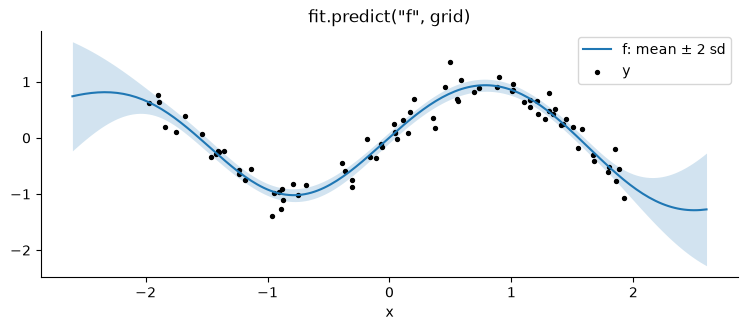

In [11]:
mean_f, var_f = fit.predict("f", grid)
print("f at x = -1, 0, 1:", fit.predict("f", [[-1.0], [0.0], [1.0]])[0].round(3))

fig, ax = plt.subplots()
band(ax, grid[:, 0], mean_f, var_f, label="f: mean ± 2 sd")
ax.scatter(X_np[:, 0], y_np, s=8, color="k", label="y")
ax.set(title='fit.predict("f", grid)', xlabel="x")
ax.legend();

### 4.2 A new observation

A new measurement isn't $f$: it's $f$ plus noise. In general it's everything the likelihood adds on top of the GP: a
link function, an exposure, random effects, a noise distribution. That's why it's written in the model, as `y_new`,
the same way `y` is. `fit.predict_new("y_new")` gives its posterior mean and variance at whatever `X_new` holds,
and **`pm.set_data` moves it**: the next call picks up the new inputs.

The two bands differ by exactly the observation noise:

y_new at the 3 inputs set in the model: [ 0.809  0.009 -1.273]
variance of y_new minus variance of f: [0.0372 0.0372 0.0372] ... = sigma² = 0.0372


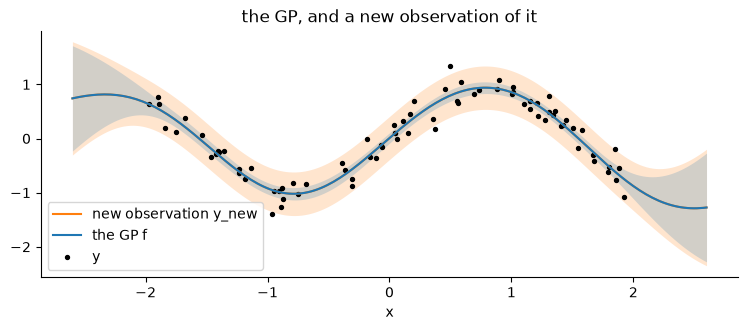

In [12]:
print("y_new at the 3 inputs set in the model:", fit.predict_new("y_new")[0].round(3))

with m:
    pm.set_data({"X_new": grid})
mean_y, var_y = fit.predict_new("y_new")

fig, ax = plt.subplots()
band(ax, grid[:, 0], mean_y, var_y, label="new observation y_new", color="C1")
band(ax, grid[:, 0], mean_f, var_f, label="the GP f", color="C0")
ax.scatter(X_np[:, 0], y_np, s=8, color="k", label="y")
ax.set(title="the GP, and a new observation of it", xlabel="x")
ax.legend()
print("variance of y_new minus variance of f:", np.round(var_y - var_f, 4)[:3], "... = sigma² =", round(fit.estimates["sigma"] ** 2, 4))

### 4.3 The training data is fixed by the fit

An exact or sparse GP predicts by conditioning on the training data. If that data changed after fitting, predictions
would quietly condition on data the fit never saw. So the fit records its training data, and prediction refuses if it
has changed. Setting it back makes prediction work again:

In [13]:
with m:
    pm.set_data({"X": X_np + 0.5})
try:
    fit.predict("f", grid)
except ValueError as e:
    print(e)
with m:
    pm.set_data({"X": X_np})
print("set back:", fit.predict("f", [[0.0]])[0].round(3))

The training data X has changed since the fit. Predictions condition on the training data, so set it back, or refit.
set back: [0.009]


## 5. One model, four approximations

The model doesn't change when the approximation does. Only `approx` does:

| Family | What it computes | Its term |
|---|---|---|
| `Exact()` | $\log p(y \mid \theta)$, with the GP integrated out exactly. Cost $O(N^3)$ | `mll[y]` |
| `VFE(Z)` | Titsias' collapsed lower bound, with $M$ inducing inputs `Z`. Cost $O(NM^2)$ | `collapsed_elbo[y]` |
| `FITC(Z)` | the FITC approximation to the marginal likelihood (not a bound) | `fitc[y]` |
| `SVGP(Z)` | an explicit $q(u) = \mathcal{N}(m, S)$ at `Z`: an ELBO $= \mathbb{E}_q[\log p(y \mid f)] - \mathrm{KL}(q(u) \,\|\, p(u))$. Works with any likelihood and with minibatches | `expected_loglik[y]` and `kl[f]` |

The inducing inputs `Z`, and SVGP's `m` and `S`, are **variational parameters**. They belong to the objective, not the
model (`obj.params`), so the model stays a statement about the data.

Exact {'ls': 0.8582, 'eta': 0.9748, 'sigma': 0.193} | variational parameters: {}
VFE   {'ls': 0.8613, 'eta': 0.9783, 'sigma': 0.193} | variational parameters: {'f_Z': (8, 1)}
FITC  {'ls': 0.5079, 'eta': 0.7877, 'sigma': 0.0933} | variational parameters: {'f_Z': (8, 1)}
SVGP  {'ls': 0.8613, 'eta': 0.9782, 'sigma': 0.193} | variational parameters: {'f_Z': (8, 1), 'f_q_mu': (8,), 'f_q_sqrt': (36,)}


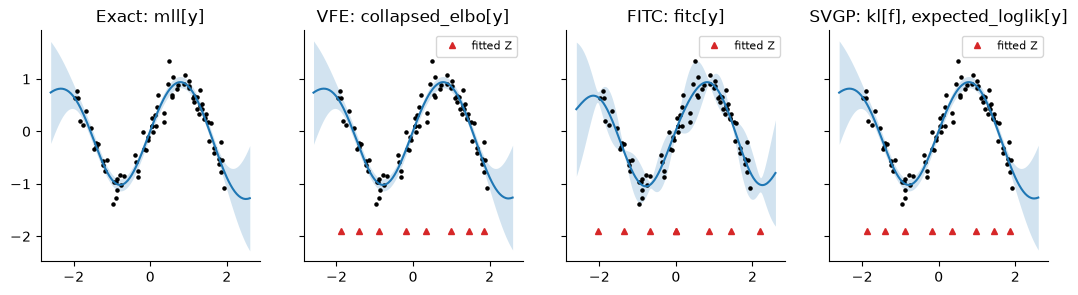

In [14]:
Z0 = np.linspace(-2, 2, 8)[:, None]
families = {"Exact": gpm.Exact(), "VFE": gpm.VFE(Z0), "FITC": gpm.FITC(Z0), "SVGP": gpm.SVGP(Z0, train_Z=True)}
fits = {}
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, (name, fam) in zip(axes, families.items()):
    o = gpm.objective(m, {"f": fam})
    fits[name] = ft = gpm.fit(o)
    band(ax, grid[:, 0], *ft.predict("f", grid))
    ax.scatter(X_np[:, 0], y_np, s=5, color="k")
    if "f_Z" in ft.params:
        ax.plot(ft.params["f_Z"][:, 0], np.full(len(Z0), -1.9), "^", color="C3", ms=5, label="fitted Z")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_title(f"{name}: " + ", ".join(t for t in o.terms if not t.startswith("logp")))
for name, ft in fits.items():
    print(f"{name:5s}", ft.estimates, "| variational parameters:", {k: x.shape for k, x in ft.params.items()})

With 8 inducing points VFE and SVGP land close to the exact fit. FITC is known to underestimate the noise, and does
here.

**Monitoring convergence.** Every fit keeps ptgp's diagnostics for each iteration in `fit.history`. For `VFE` they're
`VFEDiagnostics`, the same namedtuple ptgp's diagnostic tooling and skill pages use: the bound and its parts, the
Nyström residual (how much of the kernel the inducing points miss), the noise, and the variance budget.

VFEDiagnostics at 54 iterations; fields: elbo, fit, trace_penalty, nystrom_residual, sigma, fit_per_n, excess_fit_per_n, frac_mean, frac_signal, frac_noise, var_ratio


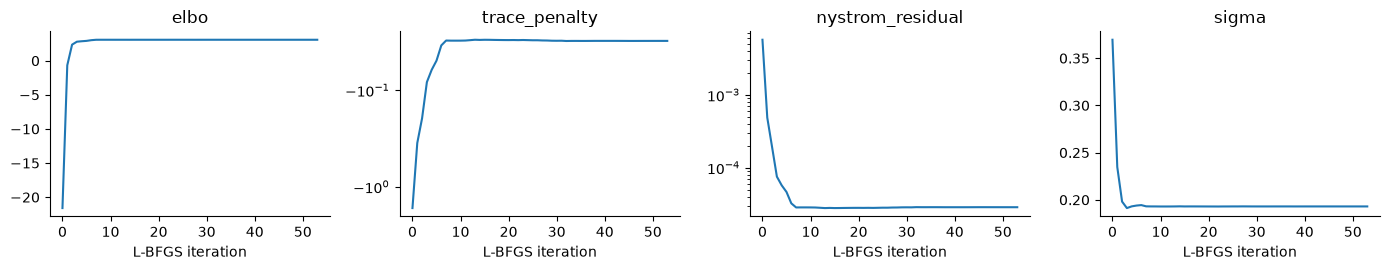

In [15]:
hist = fits["VFE"].history["f"]
print(type(hist[0]).__name__, "at", len(hist), "iterations; fields:", ", ".join(hist[0]._fields))
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, name in zip(axes, ("elbo", "trace_penalty", "nystrom_residual", "sigma")):
    ax.plot([getattr(h, name) for h in hist])
    ax.set(title=name, xlabel="L-BFGS iteration")
axes[1].set_yscale("symlog", linthresh=1e-3)
axes[2].set_yscale("log")
fig.tight_layout()

**Extra loss terms are kept separate from the bound.** Sometimes we want to add a term that isn't part of any bound:
for example a determinantal point process (DPP) regularizer that keeps inducing points apart. It goes in `penalties=`,
appears as `penalty[...]`, is included in `obj.loss`, and is left out of `obj.bound`, so the reported bound stays a
bound:

In [16]:
obj_dpp = gpm.objective(m, {"f": gpm.VFE(Z0)},
                       penalties={"dpp": lambda b: 0.1 * pg.objectives.dpp_regularizer(b.gps["f"].ptgp)})
print(obj_dpp)
bound, loss, pen = gpm.fit(obj_dpp).evaluate([obj_dpp.bound, obj_dpp.loss, obj_dpp.terms["penalty[dpp]"]])
print(f"\nbound {bound:.3f}   penalty {pen:.3f}   loss = -(bound + penalty) = {loss:.3f}")

Objective with terms:
  collapsed_elbo[y]          bound
  logp[ls]                   bound
  logp[eta]                  bound
  logp[sigma]                bound
  penalty[dpp]               penalty



bound -1.394   penalty -0.703   loss = -(bound + penalty) = 2.097


**Pointwise terms.** Data terms are also kept per observation, in `obj.pointwise`, the analogue of
`pm.compute_log_likelihood`. This is what you'd use for per-point diagnostics or a leave-one-out comparison:

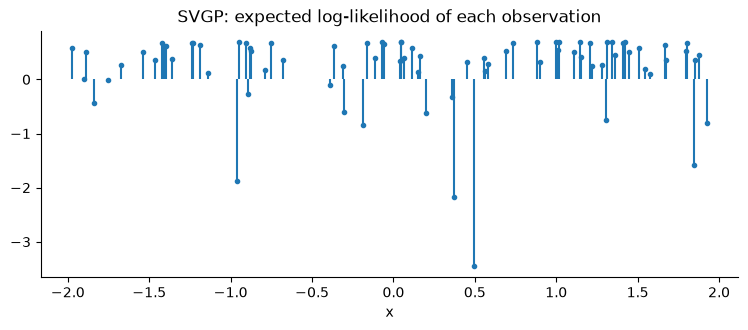

In [17]:
ft = fits["SVGP"]
pw = ft.evaluate([ft.objective.pointwise["expected_loglik[y]"]])[0]
fig, ax = plt.subplots()
ax.stem(X_np[:, 0], pw, markerfmt=".", basefmt=" ")
ax.set(title="SVGP: expected log-likelihood of each observation", xlabel="x");

## 6. Changing the model with PyMC

**`pm.do` fixes variables.** Fixing all three hyperparameters leaves nothing to fit: the objective has no inputs, and
prediction is the GP posterior at those values. **`pm.observe` turns a free variable into data.** Observing the
amplitude `eta` removes it from the fit:

pm.do: objective inputs left: [] | terms: ['mll[y]']


pm.observe(eta=1.3): free variables ['sigma', 'ls', 'f(X)', 'f(X_new)', 'y_new'] | fitted {'sigma': 0.1928, 'ls': 0.9736}


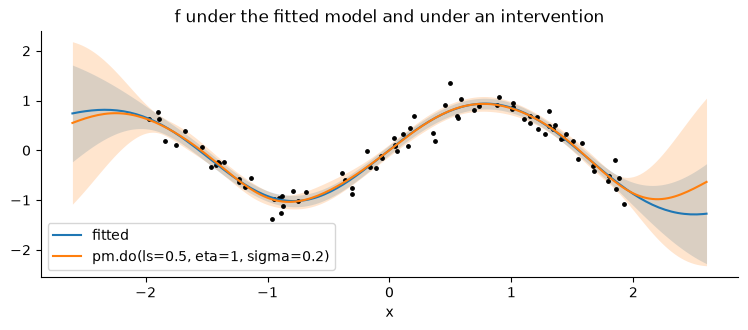

In [18]:
fixed = pm.do(m, {"ls": 0.5, "eta": 1.0, "sigma": 0.2})
o_do = gpm.objective(fixed, {"f": gpm.Exact()})
print("pm.do: objective inputs left:", o_do.inputs, "| terms:", list(o_do.terms))

observed = pm.observe(m, {"eta": 1.3})
o_obs = gpm.objective(observed, {"f": gpm.Exact()})
print("pm.observe(eta=1.3): free variables", [v.name for v in observed.free_RVs],
      "| fitted", gpm.fit(o_obs).estimates)

fig, ax = plt.subplots()
band(ax, grid[:, 0], *fit.predict("f", grid), label="fitted", color="C0")
band(ax, grid[:, 0], *gpm.fit(o_do).predict("f", grid), label="pm.do(ls=0.5, eta=1, sigma=0.2)", color="C1")
ax.scatter(X_np[:, 0], y_np, s=6, color="k")
ax.set(title="f under the fitted model and under an intervention", xlabel="x")
ax.legend();

A few things the objective refuses, each with a reason:

- **Observing `y_new` under `Exact`.** `pm.observe(m, {"y_new": ...})` is new data at the inputs `X_new`, so `f(X_new)`
  becomes a second *observed* evaluation of the GP. That's a perfectly good model, but `Exact` integrates a GP against
  one Normal likelihood, so it refuses and points to `SVGP`, which handles a GP observed any number of times
  (section 9).
- **A GP family on something that isn't a GP**, or a GP with no family.

In [19]:
for label, fn in [
    ("observe y_new, then Exact", lambda: gpm.objective(pm.observe(gp_regression(), {"y_new": np.zeros(3)}), {"f": gpm.Exact()})),
    ("no family for f", lambda: gpm.objective(gp_regression(), {})),
    ("Exact on a hyperparameter", lambda: gpm.objective(gp_regression(), {"f": gpm.Exact(), "ls": gpm.Exact()})),
]:
    try:
        fn()
    except ValueError as e:
        print(f"{label}: {e}")

observe y_new, then Exact: Exact needs one observed evaluation of f, and it has 2. Use SVGP(Z) for a GP seen through several likelihoods.
no family for f: No approximation for the GP f. Pass one of Exact, VFE, FITC, SVGP.
Exact on a hyperparameter: ls is not a GP. GP families apply to GP processes, by the GP's name.


## 7. Training on minibatches

For large data, SVGP trains on random subsets. In PyMC that's `pm.Minibatch`, plus `total_size=N` on the likelihood,
which scales each batch's log-likelihood by $N / B$ so that it's an unbiased estimate of the full-data term. The model
says this; the objective just reads it. Each call to the compiled loss draws a new batch, so the loss is noisy, and
Adam is the natural optimizer. This model has no new-observation variable: to look at the fit we only need
`fit.predict`.

2000 steps of 128 rows in 1.1s | {'ls': 0.4611, 'eta': 0.474, 'sigma': 0.2563}


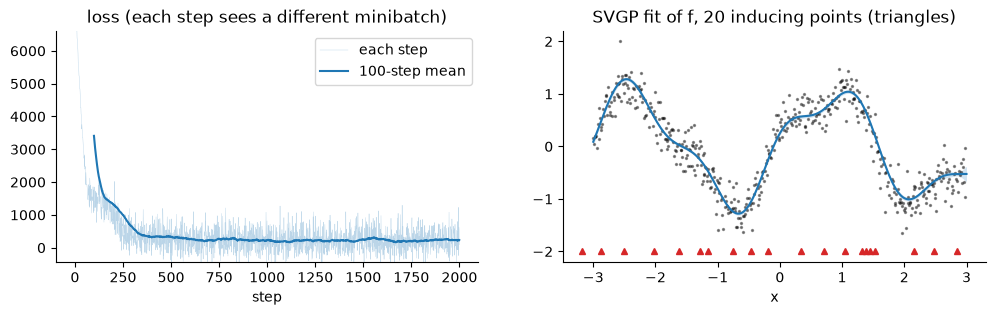

In [20]:
r = np.random.default_rng(7)
N_big = 5000
X_big = np.sort(r.uniform(-3, 3, N_big))[:, None]
y_big = np.sin(2 * X_big[:, 0]) + 0.3 * np.cos(5 * X_big[:, 0]) + 0.25 * r.standard_normal(N_big)

with pm.Model() as mb:
    Xb, yb = pm.Minibatch(X_big, y_big, batch_size=128)
    ls = pm.InverseGamma("ls", 3.0, 1.0)
    eta = pm.Exponential("eta", scale=1.0)
    sigma = pm.HalfNormal("sigma", 1.0)
    f = gpm.GP("f", eta**2 * pg.kernels.ExpQuad(input_dim=1, ls=ls))
    pm.Normal("y", mu=f(Xb), sigma=sigma, observed=yb, total_size=N_big)

obj_mb = gpm.objective(mb, {"f": gpm.SVGP(np.linspace(-3, 3, 20)[:, None], train_Z=True)})
t0 = time.time()
train_step, fit_mb = gpm.compile_training_step(obj_mb, optimizer=adam(2e-2))
for _ in range(2000):
    train_step()
print(f"2000 steps of 128 rows in {time.time() - t0:.1f}s |", fit_mb.estimates)
trace = fit_mb.trace["loss"]

xg = np.linspace(-3, 3, 200)[:, None]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3))
a1.plot(trace, lw=0.3, color="C0", alpha=0.3, label="each step")
a1.plot(np.arange(99, len(trace)), np.convolve(trace, np.ones(100) / 100, mode="valid"), color="C0", label="100-step mean")
a1.set(title="loss (each step sees a different minibatch)", xlabel="step", ylim=(np.percentile(trace, 1), np.percentile(trace, 99.5)))
a1.legend()
band(a2, xg[:, 0], *fit_mb.predict("f", xg))
a2.scatter(X_big[::10, 0], y_big[::10], s=2, color="k", alpha=0.4)
a2.plot(fit_mb.params["f_Z"][:, 0], np.full(20, -2.0), "^", color="C3", ms=4)
a2.set(title="SVGP fit of f, 20 inducing points (triangles)", xlabel="x");

## 8. Other likelihoods

The likelihood is whatever PyMC distribution the model uses. Under `SVGP`, the expected log-likelihood
$\mathbb{E}_{q(f)}[\log p(y \mid f)]$ is computed from that distribution's own `logp` (by quadrature, or in closed form
where one is known, section 2.3), so there's no separate likelihood class to write. Two examples:

- **classification:** `pm.Bernoulli(p=invprobit(f))`;
- **counts:** `pm.Poisson(mu=exp(f))`.

Here the quantity of interest is about a *new observation*: the probability that a new point is in class 1, or its
expected count. So each model writes `y_new` next to `y`, and we predict that. Its mean, $\mathbb{E}[y_\text{new}]$,
averages the link function over the posterior of $f$, which isn't the same as applying the link to the mean of $f$:

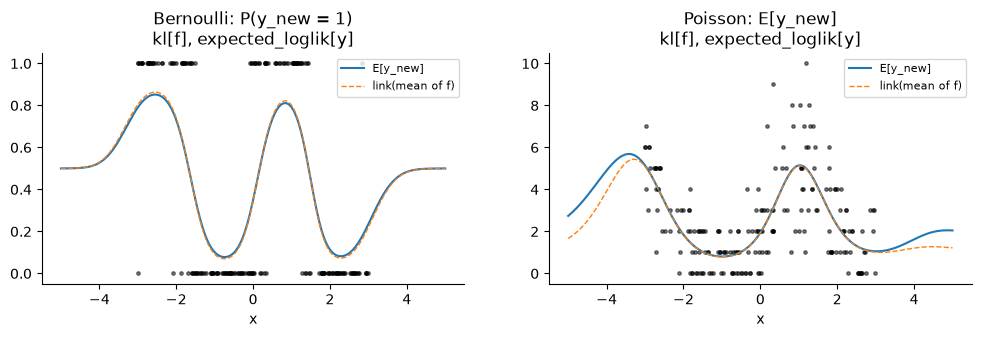

In [21]:
r = np.random.default_rng(5)
Xc = np.sort(r.uniform(-3, 3, 200))[:, None]
y_bin = (np.sin(2 * Xc[:, 0]) + 0.4 * r.standard_normal(200) > 0).astype(float)
y_cnt = r.poisson(np.exp(0.8 + 0.8 * np.sin(1.5 * Xc[:, 0]))).astype(float)
Zc = np.linspace(-3, 3, 12)[:, None]
xg = np.linspace(-5, 5, 300)[:, None]  # past the data (|x| < 3), where f is uncertain


def glm_gp(likelihood, y):
    with pm.Model() as m_:
        X = pm.Data("X", Xc)
        X_new = pm.Data("X_new", xg)
        ls = pm.InverseGamma("ls", 3.0, 1.0)
        eta = pm.Exponential("eta", scale=1.0)
        f = gpm.GP("f", eta**2 * pg.kernels.ExpQuad(input_dim=1, ls=ls))
        likelihood("y", f(X), y)
        likelihood("y_new", f(X_new), None)
    return m_


examples = {
    "Bernoulli: P(y_new = 1)": (lambda n, f, y: pm.Bernoulli(n, p=pm.math.invprobit(f), observed=y), y_bin,
                                lambda m_, v_: st.norm.cdf(m_)),
    "Poisson: E[y_new]": (lambda n, f, y: pm.Poisson(n, mu=pt.exp(f), observed=y), y_cnt, lambda m_, v_: np.exp(m_)),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, (title, (lik, y, link)) in zip(axes, examples.items()):
    m_ = glm_gp(lik, y)
    o = gpm.objective(m_, {"f": gpm.SVGP(Zc)})
    ft = gpm.fit(o)
    ax.plot(xg[:, 0], ft.predict_new("y_new")[0], label="E[y_new]")
    ax.plot(xg[:, 0], link(*ft.predict("f", xg)), "--", lw=1, label="link(mean of f)")
    ax.scatter(Xc[:, 0], y, s=6, color="k", alpha=0.5)
    ax.set(title=f"{title}\n{', '.join(t for t in o.terms if not t.startswith('logp'))}", xlabel="x")
    ax.legend(fontsize=8)

Inside the data, where $f$ is well determined, the two curves agree. Past the data ($|x| > 3$) the posterior of $f$
widens, and for the Poisson they separate: $\mathbb{E}[e^f] = e^{m + v/2}$ rises above $e^m$, so the expected count is
higher than the plug-in guess. (For the Bernoulli, both curves return to 1/2 far from the data, because the mean of $f$
returns to its prior mean of 0, so there the difference is small.) The new-observation variable gets this right
automatically, because it's computed from the likelihood itself.

## 9. One GP, seen through two likelihoods

Because a GP is one process that we can evaluate anywhere, it can be observed in more than one way. Suppose a quantity
varies along a line, and two instruments measure it:

- a few **precise readings** at 12 sites: $y_a \sim \mathcal{N}(f(X_a), \sigma)$;
- many **counts** at 300 sites, whose rate depends on the same quantity: $y_b \sim \text{Poisson}(e^{c + f(X_b)})$.

In the model that's two evaluations of one GP, each with its own likelihood:

```python
f = gpm.GP("f", kernel)
pm.Normal("y_a", mu=f(X_a), sigma=sigma, observed=y_a)
pm.Poisson("y_b", mu=pt.exp(c + f(X_b)), observed=y_b)
```

`objective` sees two observed evaluations of the same process. Under `SVGP` they're one latent over the stacked inputs
$[X_a; X_b]$, with **one** $q(u)$ and **one** `kl[f]`, and one expected log-likelihood per likelihood. Fitting the
model with both sources, and with each alone, shows what each contributes:

Objective with terms:
  kl[f]                      bound
  expected_loglik[y_a]       bound    closed form
  expected_loglik[y_b]       bound    closed form
  logp[ls]                   bound
  logp[eta]                  bound
  logp[sigma]                bound
  logp[c]                    bound
observed evaluations of f: ['f(X_a)', 'f(X_b)']


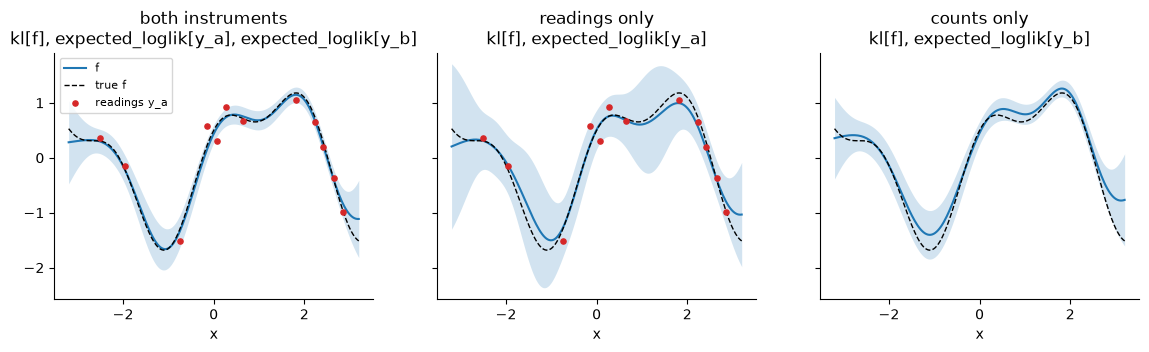

In [22]:
r = np.random.default_rng(4)
f_true = lambda x: 1.2 * np.sin(1.3 * x) + 0.5 * np.cos(3 * x)
Xa = np.sort(r.uniform(-3, 3, 12))[:, None]
ya = f_true(Xa[:, 0]) + 0.15 * r.standard_normal(12)
Xb = np.sort(r.uniform(-3, 3, 300))[:, None]
yb = r.poisson(np.exp(0.5 + f_true(Xb[:, 0]))).astype(float)
xg = np.linspace(-3.2, 3.2, 200)[:, None]


def two_instruments(readings=True, counts=True):
    with pm.Model() as m_:
        X_a, X_b = pm.Data("X_a", Xa), pm.Data("X_b", Xb)
        ls = pm.InverseGamma("ls", 3.0, 2.0)
        eta = pm.Exponential("eta", 1.0)
        f = gpm.GP("f", eta**2 * pg.kernels.ExpQuad(input_dim=1, ls=ls))
        if readings:
            sigma = pm.HalfNormal("sigma", 0.5)
            pm.Normal("y_a", mu=f(X_a), sigma=sigma, observed=ya)
        if counts:
            c = pm.Normal("c", 0.0, 1.0)
            pm.Poisson("y_b", mu=pt.exp(c + f(X_b)), observed=yb)
    return m_


Z = np.linspace(-3, 3, 15)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, (title, kw) in zip(axes, [("both instruments", {}), ("readings only", {"counts": False}),
                                  ("counts only", {"readings": False})]):
    o = gpm.objective(two_instruments(**kw), {"f": gpm.SVGP(Z)})
    band(ax, xg[:, 0], *gpm.fit(o).predict("f", xg), label="f")
    ax.plot(xg[:, 0], f_true(xg[:, 0]), "k--", lw=1, label="true f")
    if "readings" not in kw:
        ax.scatter(Xa[:, 0], ya, color="C3", s=14, zorder=3, label="readings y_a")
    ax.set(title=f"{title}\n" + ", ".join(t for t in o.terms if not t.startswith("logp")), xlabel="x")
    if title == "both instruments":
        print(o)
        print("observed evaluations of f:", [rv.name for rv, _ in o.gps["f"].gp.observed])
axes[0].legend(fontsize=8);

The readings alone pin $f$ down only near the 12 sites, with wide bands between them. The counts cover the whole
range. With both, the posterior follows the true function closely everywhere and goes through the precise readings.
Nothing about this needed a new kind of object, only a second call to the same GP.

`Exact`, `VFE` and `FITC` integrate a GP against one Normal likelihood, so they refuse a GP that's observed twice and
point to `SVGP`:

In [23]:
try:
    gpm.objective(two_instruments(), {"f": gpm.Exact()})
except ValueError as e:
    print(e)

Exact needs one observed evaluation of f, and it has 2. Use SVGP(Z) for a GP seen through several likelihoods.


## 10. More than one GP: a GP for the noise

Any parameter of any distribution can depend on a GP. Here the noise scale is **itself a GP**: $y \sim
\mathcal{N}(f, \exp(g))$ with $f$ and $g$ independent GPs, $g$ with its own mean. This is a heteroskedastic model whose
noise isn't a parametric function of $x$.

Each GP gets its own `SVGP` entry, and so its own $q(u)$ and its own KL term. The likelihood depends on both, and not
linearly (through $\exp(g)$), so the expected log-likelihood is a 2-D quadrature over $(f, g)$ at each point. After
fitting, `fit.predict` gives each GP by name:

Objective with terms:
  kl[f]                      bound
  kl[g]                      bound
  expected_loglik[y]         bound    2-D quadrature
  logp[ls_f]                 bound
  logp[eta_f]                bound
  logp[ls_g]                 bound
  logp[eta_g]                bound
  logp[mu_g]                 bound


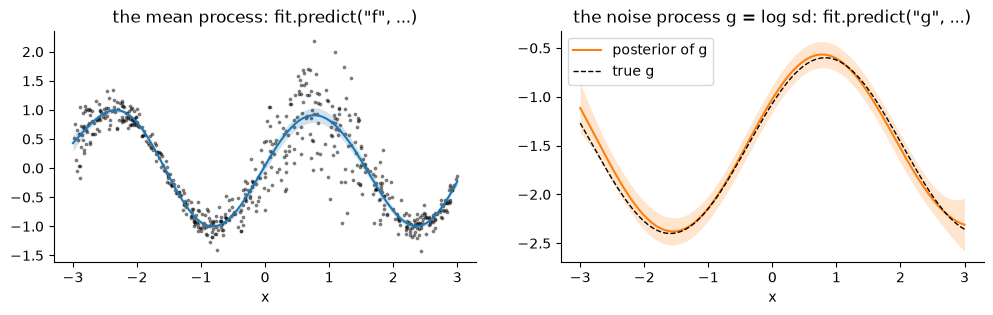

In [24]:
r = np.random.default_rng(11)
Nn = 600
Xn = np.sort(r.uniform(-3, 3, Nn))[:, None]
g_true = lambda x: -1.5 + 0.9 * np.sin(1.3 * x + 0.5)
yn = np.sin(2 * Xn[:, 0]) + np.exp(g_true(Xn[:, 0])) * r.standard_normal(Nn)

with pm.Model() as mh:
    Xb, yb = pm.Minibatch(Xn, yn, batch_size=100)
    ls_f, eta_f = pm.InverseGamma("ls_f", 3.0, 1.0), pm.Exponential("eta_f", scale=1.0)
    ls_g, eta_g = pm.InverseGamma("ls_g", 3.0, 2.0), pm.Exponential("eta_g", scale=1.0)
    mu_g = pm.Normal("mu_g", 0.0, 2.0)
    f = gpm.GP("f", eta_f**2 * pg.kernels.ExpQuad(input_dim=1, ls=ls_f))
    g = gpm.GP("g", eta_g**2 * pg.kernels.ExpQuad(input_dim=1, ls=ls_g), mean=lambda X: mu_g * pt.ones(X.shape[0]))
    pm.Normal("y", mu=f(Xb), sigma=pt.exp(g(Xb)), observed=yb, total_size=Nn)

obj_h = gpm.objective(mh, {"f": gpm.SVGP(np.linspace(-3, 3, 15)[:, None]), "g": gpm.SVGP(np.linspace(-3, 3, 10)[:, None])},
                     n_points=15)
print(obj_h)
train_step, fit_h = gpm.compile_training_step(obj_h)
for _ in range(4000):
    train_step()

xg = np.linspace(-3, 3, 200)[:, None]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3))
band(a1, xg[:, 0], *fit_h.predict("f", xg), label="f")
a1.scatter(Xn[:, 0], yn, s=3, color="k", alpha=0.4)
a1.set(title='the mean process: fit.predict("f", ...)', xlabel="x")
band(a2, xg[:, 0], *fit_h.predict("g", xg), label="posterior of g", color="C1")
a2.plot(xg[:, 0], g_true(xg[:, 0]), "k--", lw=1, label="true g")
a2.set(title='the noise process g = log sd: fit.predict("g", ...)', xlabel="x")
a2.legend();

## 11. Putting it together: predicting water-main breaks

The earlier sections each showed one feature. This one puts them together on a problem with the shape of a real
analysis.

**The problem.** A water utility owns a network of buried pipes ("mains"). Pipes break; each break is an emergency
repair. Every year the utility has to decide which pipes to replace before they fail and how much repair budget to
hold, so it wants to know, for each pipe, **how many breaks to expect next year**, with an honest uncertainty.

**The data** is a *panel*: one row per pipe per year, 300 pipes over 16 years (2010 to 2025). Each row has:

| | |
|---|---|
| the count `y` | the pipe's breaks that year. Most are zero: 956 breaks in the 4,500 training pipe-years |
| `age`, `size` | the pipe's age and diameter (standardized). Old, small pipes tend to break more |
| `year` | the calendar year. Break rates drift over time, with weather and with how the network is run |
| `history` | a summary of the pipe's past breaks. A pipe that has broken before is more likely to break again |
| `length` | the pipe's length. A pipe twice as long has twice the opportunity to break, so it enters as an **exposure** |

The data here is simulated, from the model below with known parameter values, so the fit can be checked against the
truth. Its structure follows a real analysis of a city's water-main break records.

**The model.** Breaks are counts, so $y \sim \text{Poisson}(e^\eta)$, where $\eta$ is the log of the pipe's expected
breaks that year. $\eta$ is a sum of parts, a **linear predictor**:

$$\eta = \underbrace{c}_{\text{overall level}} + \underbrace{\log(\text{length})}_{\text{exposure}}
+ \underbrace{\sqrt{v_1}\, f_\text{base}(\text{age}, \text{size})}_{\text{what kind of pipe it is}}
+ \underbrace{\sqrt{v_2}\, f_\text{trend}(\text{year})}_{\text{smooth drift over time}}
+ \underbrace{\sqrt{v_3}\, f_\text{hist}(\text{history}, \text{age})}_{\text{its track record}}
+ \underbrace{\kappa_\text{year}}_{\text{a good or bad year}} + \underbrace{\varepsilon_\text{pipe}}_{\text{frailty}}.$$

- **Three GPs** capture smooth effects whose shape we don't want to assume: how risk depends on age and size, how it
  drifts across years, and how it depends on break history. Each has its own kernel on its own columns.
- **Two random effects** capture what's left. $\kappa_\text{year} \sim \mathcal{N}(0, v_4)$ is a shock shared by every
  pipe in a year (a hard winter). $\varepsilon_\text{pipe} \sim \mathcal{N}(0, v_5)$ is the **frailty**: a pipe's own
  persistent tendency to break, beyond anything its covariates explain (bad soil, a poor installation). There's one
  per pipe, so 300 of them.
- **A variance budget.** Each GP has a unit-amplitude kernel and is scaled by $\sqrt{v_k}$, so $v_1, \dots, v_5$ say
  how much of the variation in log-rate each of the five parts accounts for. They get priors and are estimated, with
  uncertainty: "how much is the pipe's type, how much is the year, how much is the individual pipe?" is itself a
  question the utility cares about.

**What makes it a good test of the design:** five latent quantities feed one likelihood, the likelihood isn't Gaussian,
the data is large enough to want minibatches, and different parts want different treatment (GPs, random effects,
variances, lengthscales).

**Prediction.** The last year, 2025, is held out, as if we were planning for it at the end of 2024. Predicting a
pipe's breaks next year is a *new observation*, and it needs the whole likelihood: the exposure, all three GPs, the
pipe's frailty and the year's effect. So it's written in the model as `y_new`, through the same function `eta` as the
training data, at its own inputs: `X_new`, `pipe_new`, `year_new` and `logE_new` (one row per pipe-year to predict).

The code below has three parts: `make_panel` simulates the data (each GP component is a draw from a GP with a known
variance and lengthscale), `pipe_model` is the model, and the last lines split off the held-out year.

In [25]:
D = 4  # columns: age, size, year, break history (standardized)


from scipy.spatial.distance import cdist

# The data is generated from the model itself, so every parameter has a true value.
TRUE_V = np.array([0.15, 0.04, 0.08, 0.15**2, 0.5**2])  # base, trend, hist, year effect, frailty
TRUE_LS = {"base": np.array([1.0, 1.5]), "trend": 0.8, "hist": np.array([0.8, 2.0])}


def matern52(A, B, ls):
    r = cdist(A / ls, B / ls)
    return (1 + np.sqrt(5) * r + 5 * r**2 / 3) * np.exp(-np.sqrt(5) * r)


def expquad(A, B, ls):
    return np.exp(-0.5 * cdist(A / ls, B / ls) ** 2)


def gp_draw(r, kernel, X, ls, v):
    """One draw of a GP with variance v (unit-amplitude kernel times v) at the rows of X."""
    L = np.linalg.cholesky(kernel(X, X, ls) + 1e-6 * np.eye(len(X)))
    return np.sqrt(v) * (L @ r.standard_normal(len(X)))


def make_panel(n_pipes=300, years=np.arange(2010, 2026), seed=0):
    r = np.random.default_rng(seed)
    x = r.uniform(-2, 2, (n_pipes, 2))  # age, size: fixed per pipe
    h0 = r.standard_normal(n_pipes)
    logL = r.normal(0.0, 0.4, n_pipes)
    pid = np.tile(np.arange(n_pipes), len(years))
    yid = np.repeat(np.arange(len(years)), n_pipes)
    yr_unique = (years - 2017.5) / 4.6
    X = np.column_stack([x[pid], yr_unique[yid], h0[pid] + 0.1 * r.standard_normal(len(pid))])
    v1, v2, v3, v4, v5 = TRUE_V
    base = gp_draw(r, matern52, x, TRUE_LS["base"], v1)  # one value per pipe
    trend = gp_draw(r, expquad, yr_unique[:, None], TRUE_LS["trend"], v2)  # one value per year
    hist = gp_draw(r, matern52, X[:, [3, 0]], TRUE_LS["hist"], v3)  # one value per pipe-year
    kap = np.sqrt(v4) * r.standard_normal(len(years))
    eps = np.sqrt(v5) * r.standard_normal(n_pipes)
    truth = dict(f_base=base[pid], f_trend=trend[yid], f_hist=hist, trend_by_year=trend, eps=eps, kappa=kap)
    truth["eta"] = -2.0 + logL[pid] + truth["f_base"] + truth["f_trend"] + truth["f_hist"] + eps[pid] + kap[yid]
    return X, r.poisson(np.exp(truth["eta"])).astype(float), pid, yid, logL[pid], truth


def pipe_model(train, new, n_pipes, n_years, batch=512):
    Xtr, ytr, ptr, yidtr, logEtr = train
    with pm.Model() as m:
        Xb, yb, pb, yrb, Eb = pm.Minibatch(Xtr, ytr, ptr, yidtr, logEtr, batch_size=batch)
        X_new, pipe_new, year_new, logE_new = (pm.Data(k, x) for k, x in zip(("X_new", "pipe_new", "year_new", "logE_new"), new))

        logv = pm.Normal("logv", np.log(0.1), 1.0, shape=5)  # budget: base, trend, hist, year effect, frailty
        c = pm.Normal("c", -2.0, 1.0)
        ls_b = pm.InverseGamma("ls_base", 3.0, 3.0, shape=2)
        ls_t = pm.InverseGamma("ls_trend", 3.0, 3.0)
        ls_h = pm.InverseGamma("ls_hist", 3.0, 3.0, shape=2)

        f_base = gpm.GP("f_base", pg.kernels.Matern52(input_dim=D, ls=ls_b, active_dims=[0, 1]))
        f_trend = gpm.GP("f_trend", pg.kernels.ExpQuad(input_dim=D, ls=ls_t, active_dims=[2]))
        f_hist = gpm.GP("f_hist", pg.kernels.Matern52(input_dim=D, ls=ls_h, active_dims=[3, 0]))
        kappa = pm.Normal("kappa", 0.0, pt.exp(0.5 * logv[3]), shape=n_years)
        eps = pm.Normal("eps", 0.0, pt.exp(0.5 * logv[4]), shape=n_pipes)
        sd = pt.exp(0.5 * logv)

        def eta(X, logE, pipe, year):  # the linear predictor
            return (c + logE + sd[0] * f_base(X) + sd[1] * f_trend(X) + sd[2] * f_hist(X)
                    + kappa[pt.cast(year, "int64")] + eps[pt.cast(pipe, "int64")])

        pm.Poisson("y", pt.exp(eta(Xb, Eb, pb, yrb)), observed=yb, total_size=len(ytr))
        pm.Poisson("y_new", pt.exp(eta(X_new, logE_new, pipe_new, year_new)))
    return m


Xp, yp, pidp, yidp, logEp, truth = make_panel()
n_pipes, n_years = 300, 16
tr, te = yidp < n_years - 1, yidp == n_years - 1
train = (Xp[tr], yp[tr], pidp[tr], yidp[tr], logEp[tr])
held_out = (Xp[te], pidp[te], yidp[te], logEp[te])
mp = pipe_model(train, held_out, n_pipes, n_years)
print(f"{tr.sum()} training pipe-years, {te.sum()} held out, {int(yp[tr].sum())} training breaks")

4500 training pipe-years, 300 held out, 956 training breaks


**Choosing how each part is fitted.** This is where the families for non-GP variables come in:

| Variables | Family | What it does |
|---|---|---|
| `f_base`, `f_trend`, `f_hist` | `SVGP(Z)` | $q(u)$ per GP, KL to the GP prior |
| `kappa`, `eps` | `MeanField()` | $q = \mathcal{N}(m, s^2)$ per element, KL to the Normal prior in closed form |
| `logv`, `c` | `Gaussian(draws=16)` | a Gaussian over the budget, its expectations averaged over **16 fixed draws**, plus its entropy |
| the lengthscales | `Point` (default) | point estimates, with their log priors |

Fixed draws make the budget's part of the objective an ordinary deterministic function, a sample-average
approximation, so it can be optimized like any other loss and the run is reproducible.

**The linear predictor is found automatically.** The likelihood depends on five latents (three GPs and two random
effects), but only through $\eta$, which is **affine** in them. `objective` finds $\eta$ in the graph, adds up the
means and variances each latent contributes to it, and takes the expectation over $\eta$ alone. For a Poisson with a
log link that's a closed form (the objective below says so). Without the linear predictor it would be a grid over five
latents: $20^5 = 3.2$ million evaluations per row.

In [26]:
Zb = Xp[np.random.default_rng(0).choice(tr.sum(), 32, replace=False)]
Zt = np.zeros((n_years - 1, D))
Zt[:, 2] = np.unique(Xp[tr, 2])  # one inducing point per training year
Zh = Xp[np.random.default_rng(1).choice(tr.sum(), 16, replace=False)]

approx_vi = {
    "f_base": gpm.SVGP(Zb, train_Z=True),
    "f_trend": gpm.SVGP(Zt),
    "f_hist": gpm.SVGP(Zh, train_Z=True),
    "kappa": gpm.MeanField(),
    "eps": gpm.MeanField(),
    ("logv", "c"): gpm.Gaussian(draws=16, seed=42),
}
obj_p = gpm.objective(mp, approx_vi)
obj_p

Objective with terms:
  kl[f_base]                 bound
  kl[f_trend]                bound
  kl[f_hist]                 bound
  kl[kappa]                  bound
  kl[eps]                    bound
  expected_loglik[y]         bound    closed form
  logp[logv]                 bound
  logp[c]                    bound
  entropy[logv+c]            bound
  logp[ls_base]              bound
  logp[ls_trend]             bound
  logp[ls_hist]              bound

Each term is labelled by the variable it belongs to: three GP KLs, two random-effect KLs, one data term, the budget's
averaged log prior and its entropy, and the lengthscale priors. That's the ELBO, decomposed.

We fit with `pm.Minibatch` and Adam, then score the held-out year with `fit.log_predictive("y_new", y_test)`:
the log density of the actual held-out counts under the predicted distribution of `y_new`, integrated over $q$ and
averaged over the budget's draws.

fitted in 3s | held-out log predictive density -137.3


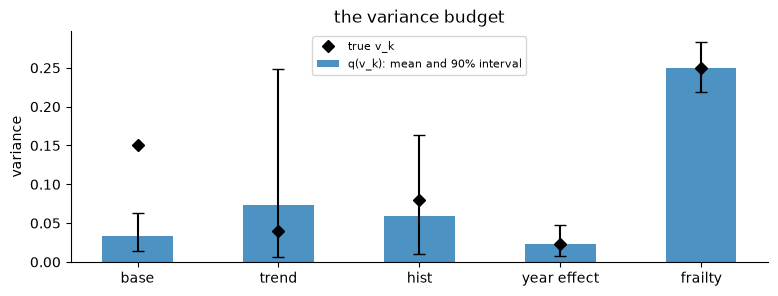

In [27]:
t0 = time.time()
train_step, fit_p = gpm.compile_training_step(obj_p)
for _ in range(2000):
    train_step()
v_fit = fit_p.params
lpd = fit_p.log_predictive("y_new", yp[te])
print(f"fitted in {time.time() - t0:.0f}s | held-out log predictive density {lpd.sum():.1f}")

# q(log v) is Gaussian, so each v_k is lognormal under q: its mean and a 90% interval
loc, s = v_fit["logv+c_loc"][:5], np.exp(v_fit["logv+c_logsd"][:5])
v_mean, v_lo, v_hi = np.exp(loc + 0.5 * s**2), np.exp(loc - 1.645 * s), np.exp(loc + 1.645 * s)

labels = ["base", "trend", "hist", "year effect", "frailty"]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(np.arange(5), v_mean, 0.5, yerr=[v_mean - v_lo, v_hi - v_mean], capsize=4, color="C0", alpha=0.8,
       label="q(v_k): mean and 90% interval")
ax.plot(np.arange(5), TRUE_V, "D", color="k", label="true v_k")
ax.set_xticks(np.arange(5), labels)
ax.set(title="the variance budget", ylabel="variance")
ax.legend(fontsize=8);

**Checking against the truth.** The data was generated from the model itself, with the true $v_k$ shown as
diamonds, so every bar has a target. What the plot shows:

- **The random effects are recovered:** both true variances are inside their intervals. Each is seen through many
  independent values (300 frailties, 15 year effects), and a sample of many independent values pins down their
  variance.
- **A GP's variance is only loosely determined by one curve.** The data contain one draw of each GP function, and a
  smooth draw spreads less over the observed inputs than its $v_k$: this trend draw, for example, has variance 0.005
  across its 16 years, against $v_2 = 0.04$. So the trend's interval is wide, which is the honest answer.
- **The base component is under-estimated**, with its truth outside the interval. Base and frailty both vary from pipe
  to pipe, and with about three breaks per pipe the data can only partly tell a smooth function of age and size from
  pipe-specific variation; $q$ also treats the two as independent, so it can't represent their trade-off. Checked
  outside this notebook: training 3× longer or with 3× as many inducing points leaves the estimate unchanged, while
  shrinking the true frailty variance from 0.25 to 0.02 roughly doubles it. These intervals come from the
  approximation $q$, not the exact posterior, and this is where that shows.

The fitted frailties themselves are the means of $q(\varepsilon)$, one per pipe. Most pipes have only a few breaks in
15 years, so each frailty is shrunk strongly toward zero and its interval is wide: that's the posterior being honest,
not a poor fit. The year effects are better determined (300 pipes inform each year), and the held-out year has no data,
so its $q(\kappa)$ stays at the prior:

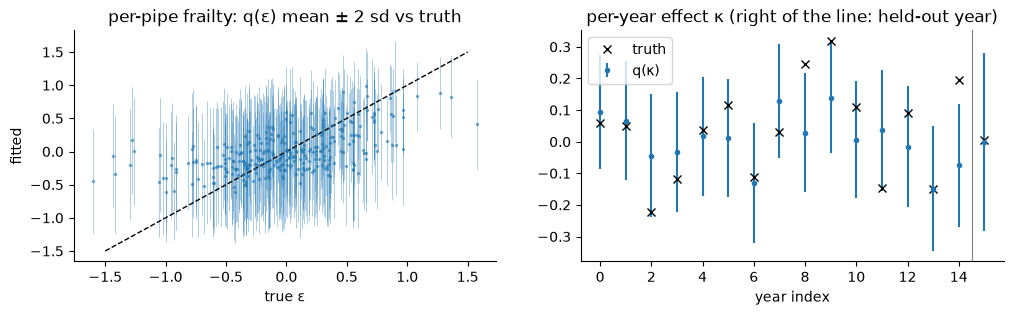

In [28]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3))
a1.errorbar(truth["eps"], v_fit["eps_m"], yerr=2 * np.exp(v_fit["eps_log_s"]), fmt=".", ms=3, alpha=0.5, elinewidth=0.5)
a1.plot([-1.5, 1.5], [-1.5, 1.5], "k--", lw=1)
a1.set(title="per-pipe frailty: q(ε) mean ± 2 sd vs truth", xlabel="true ε", ylabel="fitted")
a2.errorbar(np.arange(n_years), v_fit["kappa_m"], yerr=2 * np.exp(v_fit["kappa_log_s"]), fmt="o", ms=3, label="q(κ)")
a2.plot(np.arange(n_years), truth["kappa"], "kx", label="truth")
a2.axvline(n_years - 1.5, color="gray", lw=0.8)
a2.set(title="per-year effect κ (right of the line: held-out year)", xlabel="year index")
a2.legend();

**Both kinds of prediction, on this model.**

*The GPs.* Each component is a GP in its own right, so `fit.predict` shows it on its own. The trend GP reads only the
year column, so evaluating it on a grid of years shows the fitted calendar trend. It's unit-amplitude, so it's scaled by
the fitted $\sqrt{v_2}$ here:

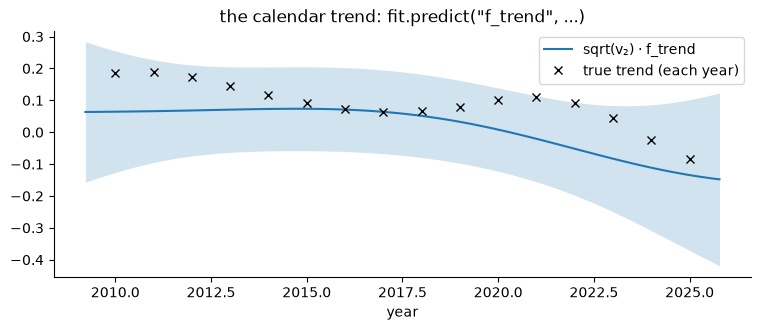

In [29]:
years = np.linspace(-1.8, 1.8, 100)
X_years = np.zeros((100, D))
X_years[:, 2] = years
m_t, v_t = fit_p.predict("f_trend", X_years)
scale = np.sqrt(v_mean[1])
fig, ax = plt.subplots()
band(ax, years * 4.6 + 2017.5, scale * m_t, scale**2 * v_t, label="sqrt(v₂) · f_trend")
ax.plot(np.arange(2010, 2026), truth["trend_by_year"], "kx", label="true trend (each year)")
ax.set(title='the calendar trend: fit.predict("f_trend", ...)', xlabel="year")
ax.legend();

*New observations.* `y_new` reads four inputs, one row per pipe-year to predict. To predict for a different set of
pipe-years, set **all four together** in one `pm.set_data` call. Setting only some of them leaves them with different
numbers of rows, and prediction says so. Here we predict next year's breaks for the first 5 pipes only:

In [30]:
first5 = tuple(x[:5] for x in held_out)
with mp:
    pm.set_data({"X_new": first5[0]})
try:
    fit_p.predict_new("y_new")
except ValueError as e:
    print(e)

with mp:
    pm.set_data(dict(zip(("X_new", "pipe_new", "year_new", "logE_new"), first5)))
mean_new, var_new = fit_p.predict_new("y_new")
print("\nexpected breaks next year, first 5 pipes:", mean_new.round(3))
print("true rate                               :", np.exp(truth["eta"][te][:5]).round(3))

The prediction inputs have different numbers of rows: {'X_new': 5, 'pipe_new': 300, 'year_new': 300, 'logE_new': 300}. Set them together, in one pm.set_data call.

expected breaks next year, first 5 pipes: [0.201 0.278 0.176 0.225 0.144]
true rate                               : [0.225 0.213 0.11  0.298 0.073]


## 12. Additive GPs: a sum of GPs, fitted as one GP

A sum of independent GPs is itself a GP, and its kernel is the sum of their kernels: if
$f_a \sim \mathcal{GP}(0, k_a)$ and $f_b \sim \mathcal{GP}(0, k_b)$, then $f_a + f_b \sim \mathcal{GP}(0, k_a + k_b)$.
The two ways of looking at it differ in what they cost and what they show:

- **as one GP with a summed kernel**, there's one covariance matrix to factor, and the exact and sparse marginal
  likelihoods apply. But the parts are hidden inside the sum;
- **as separate GPs** (as in section 11), each part is visible, but each gets its own approximation, and an exact fit
  isn't available.

Here the model is written the natural way, as GPs added together, and it's *fitted* as one GP:

```python
f_a, f_b = gpm.GP("f_a", k_a), gpm.GP("f_b", k_b)
pm.Normal("y", mu=f_a(X) + f_b(X), sigma=sigma, observed=y)

obj = gpm.objective(model, {("f_a", "f_b"): gpm.Exact()})
```

This works because a GP evaluation is a typed node in the graph. `f_a(X) + f_b(X)` is an `Add` node whose inputs are
two `GPRV` nodes with the same rows input, and `gpm.find_gp_sums` matches that pattern. It allows a scalar in front of
each GP, and other terms in the sum that don't involve a GP (an intercept, an exposure, a random effect). Nothing in
the model declares that the GPs belong together; giving them one family, keyed by a **tuple** of their names, says to
fit them as one GP with kernel $\sum_k c_k^2 k_k$.

Each GP's own posterior is still available afterwards, with `fit.predict("f_a", X)`. A part and the data are jointly
Gaussian, with $\text{Cov}(f_a(x_*), y) = k_a(x_*, X)$, so the part's posterior is the usual GP formula with $k_a$ in
the cross-covariance and prior variance, and the summed kernel everywhere else. No extra fitting is involved.

The example is the classic additive model over two inputs, $y = f_a(x_1) + f_b(x_2) + \text{noise}$, fitted exactly:

found in y's mean: a sum of ['f_a', 'f_b'] at rows X 

Objective with terms:
  mll[y]                     bound
  logp[ls]                   bound
  logp[eta]                  bound
  logp[sigma]                bound


{'ls': [1.2296, 1.3256], 'eta': [1.2075, 1.5097], 'sigma': 0.2073}
f_a: average of its posterior mean over the grid  0.62


f_b: average of its posterior mean over the grid -0.61


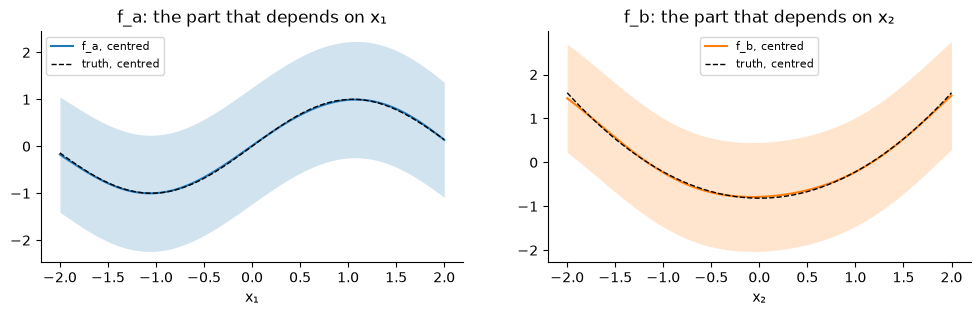

In [31]:
r = np.random.default_rng(2)
Xadd = r.uniform(-2, 2, (300, 2))
fa_true = lambda x: np.sin(1.5 * x)
fb_true = lambda x: 0.6 * (x**2 - 4 / 3)  # both parts average to zero over [-2, 2]
yadd = fa_true(Xadd[:, 0]) + fb_true(Xadd[:, 1]) + 0.2 * r.standard_normal(300)
Xt = r.uniform(-2, 2, (5, 2))  # where to predict

with pm.Model() as m_two:
    X = pm.Data("X", Xadd)
    X_new = pm.Data("X_new", Xt)
    ls = pm.InverseGamma("ls", 3.0, 2.0, shape=2)
    eta = pm.Exponential("eta", scale=1.0, shape=2)
    sigma = pm.HalfNormal("sigma", 1.0)
    f_a = gpm.GP("f_a", eta[0] ** 2 * pg.kernels.ExpQuad(input_dim=2, ls=ls[0], active_dims=[0]))
    f_b = gpm.GP("f_b", eta[1] ** 2 * pg.kernels.ExpQuad(input_dim=2, ls=ls[1], active_dims=[1]))
    pm.Normal("y", mu=f_a(X) + f_b(X), sigma=sigma, observed=yadd)
    pm.Normal("y_new", mu=f_a(X_new) + f_b(X_new), sigma=sigma)

# what the pattern match finds in the graph of y's mean
evals = {m_two["f_a(X)"]: "f_a", m_two["f_b(X)"]: "f_b"}
(found,) = gpm.find_gp_sums(list(m_two["y"].owner.inputs), evals)
print("found in y's mean: a sum of", list(found.terms), "at rows", found.rows.name, "\n")

obj_two = gpm.objective(m_two, {("f_a", "f_b"): gpm.Exact()})
print(obj_two)
fit_two = gpm.fit(obj_two)
print(fit_two.estimates)

xg = np.linspace(-2, 2, 100)
grid_a, grid_b = np.c_[xg, np.zeros(100)], np.c_[np.zeros(100), xg]  # each GP ignores the other column
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3))
for ax, name, grid_, truth_, color in [(a1, "f_a", grid_a, fa_true, "C0"), (a2, "f_b", grid_b, fb_true, "C1")]:
    mean_, var_ = fit_two.predict(name, grid_)
    print(f"{name}: average of its posterior mean over the grid {mean_.mean(): .2f}")
    band(ax, xg, mean_ - mean_.mean(), var_, label=f"{name}, centred", color=color)
    ax.plot(xg, truth_(xg) - truth_(xg).mean(), "k--", lw=1, label="truth, centred")
    ax.set(title=f"{name}: the part that depends on x{'₁' if name == 'f_a' else '₂'}", xlabel=f"x{'₁' if name == 'f_a' else '₂'}")
    ax.legend(fontsize=8)

The objective has a single `mll[y]` term: the two GPs were integrated out together as one exact GP, with one
factorization. Each GP comes out separately anyway, and each has the right shape.

**Reading the plot.** Only the sum $f_a + f_b$ is tied down by the data, so a constant can move freely from one GP to
the other. The printed averages show it: the two are offset by equal and opposite amounts. The curves are therefore
drawn centred (each with its average over the grid removed), and the bands are wide because they include the
uncertainty about that constant, not because the shape is uncertain. An explicit intercept in the model, or a
sum-to-zero constraint on the parts, would remove it.

**It is the same fit as one GP with the summed kernel.** The check below writes that model directly, with the kernel
`k_a + k_b`, and compares:

In [32]:
with pm.Model() as m_one:
    X = pm.Data("X", Xadd)
    ls = pm.InverseGamma("ls", 3.0, 2.0, shape=2)
    eta = pm.Exponential("eta", scale=1.0, shape=2)
    sigma = pm.HalfNormal("sigma", 1.0)
    f = gpm.GP("f", eta[0] ** 2 * pg.kernels.ExpQuad(input_dim=2, ls=ls[0], active_dims=[0])
               + eta[1] ** 2 * pg.kernels.ExpQuad(input_dim=2, ls=ls[1], active_dims=[1]))
    pm.Normal("y", mu=f(X), sigma=sigma, observed=yadd)

fit_one = gpm.fit(gpm.objective(m_one, {"f": gpm.Exact()}))
print("same estimates:", fit_two.estimates == fit_one.estimates)
print("largest difference in the sum's posterior mean and variance:",
      max(np.abs(a - b).max() for a, b in zip(fit_two.predict("f_a+f_b", Xt), fit_one.predict("f", Xt))))
print("the two GPs' means add up to the sum's mean:",
      np.allclose(fit_two.predict("f_a", Xt)[0] + fit_two.predict("f_b", Xt)[0], fit_two.predict("f_a+f_b", Xt)[0]))

same estimates: True


largest difference in the sum's posterior mean and variance: 0.0
the two GPs' means add up to the sum's mean: True


**The same recognition is used for prediction, and it matters.** After seeing data, the two GPs are strongly
(negatively) correlated: the data pin down their sum, not each one. `y_new` reads `f_a(X_new) + f_b(X_new)`, so its
variance has to come from the posterior of the sum. Because the sum is a recognizable node, prediction replaces it by
one quantity with the right moments. Adding up the two GPs' variances as if they were independent would be badly
wrong:

In [33]:
mean_new, var_new = fit_two.predict_new("y_new")
var_sum = fit_two.predict("f_a+f_b", Xt)[1]
var_naive = fit_two.predict("f_a", Xt)[1] + fit_two.predict("f_b", Xt)[1]
s2 = fit_two.estimates["sigma"] ** 2
print("variance of y_new:                               ", var_new.round(3))
print("variance of the sum's posterior + sigma²:        ", (var_sum + s2).round(3))
print("variances of the two GPs added up + sigma²:      ", (var_naive + s2).round(3), " (wrong)")

variance of y_new:                                [0.044 0.044 0.044 0.048 0.046]
variance of the sum's posterior + sigma²:         [0.044 0.044 0.044 0.048 0.046]
variances of the two GPs added up + sigma²:       [0.811 0.81  0.814 0.807 0.807]  (wrong)


The exact families refuse the pair unless they're told it's a sum, and say how:

In [34]:
try:
    gpm.objective(m_two, {"f_a": gpm.Exact(), "f_b": gpm.Exact()})
except ValueError as e:
    print(e)

y reads more than one GP that's integrated out exactly (['f_a', 'f_b']). To fit a sum of GPs as one GP, give them one family as a tuple, e.g. {('f_a', 'f_b'): Exact()}.


**Which families take a sum.**

| Family on a tuple of GPs | Needs | Fitted as |
|---|---|---|
| `Exact()`, `VFE(Z)`, `FITC(Z)` | one Normal likelihood whose mean is the sum (plus terms without a GP) | one GP integrated out: `mll[y]`, `collapsed_elbo[y]` or `fitc[y]` |
| `SVGP(Z)` | the sum inside any likelihoods, with the same coefficients; minibatches allowed | one $q(u)$ for the sum, at one set of inducing points: `kl[f_a+f_b]` |

**When to use which.** Fitting a sum as one GP is the right choice when an exact or collapsed fit applies (a Normal
likelihood), as in the example above: one factorization, no variational parameters, and the parts still come out.
It's also what makes the GPs' posteriors correlated, which separate approximations can't represent.

Separate approximations suit GPs that live on different inputs, as in section 11. There each GP gets inducing points
in its own low-dimensional space (15 points on the year axis for the trend), where one `SVGP` on the sum needs
inducing points that cover all the inputs jointly. The scales $\sqrt{v_k}$ also sit outside the kernels there, so
draws of the variance budget don't refactor any kernel matrix; under the sum they'd be inside it. Either way the model
is written once, as a sum of GPs, and the choice is made in `approx`.

## 13. What typed nodes buy: GPs, kernels and likelihoods as Ops

In a model's graph, three things are **typed nodes**, each an Op of a recognizable class:

| | Node type | What it carries |
|---|---|---|
| a GP evaluation | `GPRV` | its process, its rows, its kernel and mean as functions of its parameter inputs |
| a kernel | `KernelOp` subclasses (`ExpQuadOp`, `Matern52Op`, ...) | which kernel it is, which columns it reads, its parameters as inputs |
| a likelihood | PyMC's random-variable Ops (`NormalRV`, `PoissonRV`, ...) | which distribution it is, its parameters as inputs |

A typed node is something code can find, inspect and replace. A plain expression (a matrix that happens to be a
covariance, a term that happens to be a log density) isn't. The rest of this section is four things that follow.

### 13.1 A model can be read

Everything below is found by walking the graph of the water-main model from section 11 and looking at node types.
Nothing was recorded on the side when the model was built.

In [35]:
from ptgp.kernels.base import KernelOp


def describe(model):
    for gp in gpm.processes(model):
        leaves = [a.owner.op for a in ancestors([gp.kernel.graph]) if a.owner is not None and isinstance(a.owner.op, KernelOp)]
        kernels = ", ".join(f"{type(op).__name__} on columns {list(op.active_dims)}" for op in leaves)
        params = [i.name or "an expression" for i in gp.observed[0][0].owner.inputs[2:]]
        print(f"GP {gp.name!r}: kernel = {kernels}; parameters {params}; "
              f"{len(gp.observed)} observed evaluation(s), {len(gp.predictive)} for prediction")
    for y in model.observed_RVs:
        node = y.owner.inputs[0].owner if type(y.owner.op).__name__ == "MinibatchRandomVariable" else y.owner
        reads = sorted({a.name for a in ancestors([y]) if a in model.free_RVs})
        print(f"likelihood {y.name!r}: {type(node.op).__name__}"
              f"{' on minibatches' if node is not y.owner else ''}, reads {reads}")


describe(mp)

GP 'f_base': kernel = Matern52Op on columns [0, 1]; parameters ['ls_base']; 1 observed evaluation(s), 1 for prediction
GP 'f_trend': kernel = ExpQuadOp on columns [2]; parameters ['ls_trend']; 1 observed evaluation(s), 1 for prediction
GP 'f_hist': kernel = Matern52Op on columns [3, 0]; parameters ['ls_hist']; 1 observed evaluation(s), 1 for prediction
likelihood 'y': PoissonRV on minibatches, reads ['c', 'eps', 'f_base(minibatch.0)', 'f_hist(minibatch.0)', 'f_trend(minibatch.0)', 'kappa', 'logv', 'ls_base', 'ls_hist', 'ls_trend']


### 13.2 Algebra on GPs: a sum of GPs is recognized

Section 12 is the example. `f_a(X) + f_b(X)` is an `Add` node over two `GPRV` nodes with the same rows input, so
`gpm.find_gp_sums` can match it, and a family given to the tuple of GPs fits the sum as one GP. The same match is
used again at prediction, so that a new observation reading the sum gets the sum's posterior. If GP values were plain
vectors in the graph, there would be nothing to match: the sum would be an ordinary sum of two unknowns.

### 13.3 The likelihood's type chooses the method

The likelihood is a node whose type says which distribution it is, so the expected log-likelihood can be chosen by
looking at it: a formula where one is known for that type on a linear predictor, quadrature otherwise (section 2.3).
The model code only changes in the likelihood line. Here is the route taken for five likelihoods on the same GP:

In [36]:
r_ = np.random.default_rng(0)
X_l = r_.uniform(-2, 2, (60, 1))
noise_gp = lambda X: gpm.GP("g", pg.kernels.ExpQuad(input_dim=1, ls=1.0))(X)
likelihoods = {
    "pm.Normal(mu=f)": (lambda f, X: pm.Normal("y", mu=f, sigma=0.3, observed=r_.normal(size=60))),
    "pm.Poisson(mu=exp(f))": (lambda f, X: pm.Poisson("y", mu=pt.exp(f), observed=r_.poisson(2.0, 60))),
    "pm.Bernoulli(p=invprobit(f))": (lambda f, X: pm.Bernoulli("y", p=pm.math.invprobit(f), observed=r_.integers(0, 2, 60))),
    "pm.StudentT(nu=4, mu=f)": (lambda f, X: pm.StudentT("y", nu=4, mu=f, sigma=0.3, observed=r_.normal(size=60))),
    "pm.Normal(mu=f, sigma=exp(g))": (lambda f, X: pm.Normal("y", mu=f, sigma=pt.exp(noise_gp(X)), observed=r_.normal(size=60))),
}
Z_l = np.linspace(-2, 2, 6)[:, None]
for label, lik in likelihoods.items():
    with pm.Model() as m_l:
        X = pm.Data("X", X_l)
        lik(gpm.GP("f", pg.kernels.ExpQuad(input_dim=1, ls=1.0))(X), X)
    o = gpm.objective(m_l, {gp.name: gpm.SVGP(Z_l) for gp in gpm.processes(m_l)})
    print(f"{label:32s} {type(m_l['y'].owner.op).__name__:12s} -> {o.routes['expected_loglik[y]']}")

pm.Normal(mu=f)                  NormalRV     -> closed form
pm.Poisson(mu=exp(f))            PoissonRV    -> closed form


pm.Bernoulli(p=invprobit(f))     BernoulliRV  -> 1-D quadrature
pm.StudentT(nu=4, mu=f)          StudentTRV   -> 1-D quadrature
pm.Normal(mu=f, sigma=exp(g))    NormalRV     -> 2-D quadrature


### 13.4 Kernel nodes carry structure to the compiler

A kernel node knows what it is, and that both of its row inputs are the same `X`, which makes its output symmetric
and positive definite. That fact travels with the node, so when the loss is compiled PyTensor can choose a Cholesky
factorization and share it between the loss and all of its gradients. The typed nodes themselves are gone by then:
they're replaced by their contents once every rewrite that needs to recognize them has run.

For the exact fit of section 12, here is what the user's graph contains, and what actually runs:

In [37]:
from collections import Counter

CUBIC = {"Cholesky", "MatrixInverse", "Solve", "SLogDet", "Det", "LUFactor"}
count = lambda nodes: dict(Counter(type(getattr(n.op, "core_op", n.op)).__name__ for n in nodes))

loss = obj_two.loss
before = count({v.owner for v in ancestors([loss]) if v.owner is not None})
variables = list(obj_two.inputs)
fn = pytensor.function(variables, [loss, *pt.grad(loss, variables)])
after = count(fn.maker.fgraph.apply_nodes)

print("in the loss graph as built:   kernel nodes", {k: v for k, v in before.items() if k.endswith("Op") and "Quad" in k},
      "| O(N³) operations", {k: v for k, v in before.items() if k in CUBIC})
print("in the compiled loss + grads: kernel nodes", {k: v for k, v in after.items() if k.endswith("Op") and "Quad" in k},
      "| O(N³) operations", {k: v for k, v in after.items() if k in CUBIC})

in the loss graph as built:   kernel nodes {'ExpQuadOp': 2} | O(N³) operations {'MatrixInverse': 1, 'Det': 1}
in the compiled loss + grads: kernel nodes {} | O(N³) operations {'Cholesky': 1}


**In short,** because GPs, kernels and likelihoods are typed nodes:

- a model can be inspected, and tools can be written against it, without the model declaring anything extra (13.1);
- structure the user wrote naturally can be recognized and used: a sum of GPs becomes one GP, for fitting and for
  prediction (section 12);
- methods are chosen by type: a closed form for a known likelihood, a factorization for a known matrix structure
  (13.3, 13.4);
- PyMC's transformations (`pm.do`, `pm.observe`) carry the nodes along, so a GP's kernel follows an intervention
  (section 2.1).

The same mechanism is where further structure would go: a product of kernels on separate inputs as a Kronecker
factorization, or a GP on a regular grid, are also patterns of typed nodes.

## 14. Correlated outputs

Several related outputs can share one GP over `(x, task)` with a coregionalization kernel, which learns how the tasks
covary. Here task 1 is only observed for $x < 0$; because it's correlated with task 0, the model still predicts it for
$x > 0$. The kernel is a product of a kernel on `x` and a low-rank kernel on the task index, each restricted to its own
column with `active_dims`. To see task 1, we ask `fit.predict` for the GP at inputs whose task column is 1.

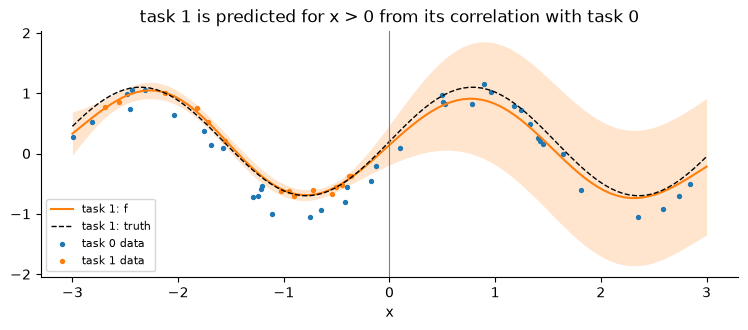

In [38]:
r = np.random.default_rng(3)
x0 = np.sort(r.uniform(-3, 3, 40))
x1 = np.sort(r.uniform(-3, 0, 15))
X2 = np.vstack([np.c_[x0, np.zeros_like(x0)], np.c_[x1, np.ones_like(x1)]])
y2 = np.r_[np.sin(2 * x0), 0.9 * np.sin(2 * x1) + 0.2] + 0.1 * r.standard_normal(55)

with pm.Model() as mc:
    X = pm.Data("X", X2)
    ls = pm.InverseGamma("ls", 3.0, 1.0)
    W = pm.Normal("W", 0, 1, shape=(2, 1))
    kappa = pm.HalfNormal("kappa", 0.5, shape=2)
    sigma = pm.HalfNormal("sigma", 1.0)
    kernel = pg.kernels.ExpQuad(input_dim=2, ls=ls, active_dims=[0]) * pg.kernels.LowRankCategorical(
        input_dim=2, num_levels=2, W=W, kappa=kappa, active_dims=[1])
    f = gpm.GP("f", kernel)
    pm.Normal("y", mu=f(X), sigma=sigma, observed=y2)

o = gpm.objective(mc, {"f": gpm.Exact()})
xs = np.linspace(-3, 3, 100)
mean, var_ = gpm.fit(o, start={"W": np.array([[1.0], [1.0]])}).predict("f", np.c_[xs, np.ones_like(xs)])
fig, ax = plt.subplots()
band(ax, xs, mean, var_, label="task 1: f", color="C1")
ax.plot(xs, 0.9 * np.sin(2 * xs) + 0.2, "k--", lw=1, label="task 1: truth")
ax.scatter(x0, y2[:40], s=8, color="C0", label="task 0 data")
ax.scatter(x1, y2[40:], s=8, color="C1", label="task 1 data")
ax.axvline(0, color="gray", lw=0.8)
ax.set(title="task 1 is predicted for x > 0 from its correlation with task 0", xlabel="x")
ax.legend(fontsize=8);

## 15. Optimizers: parameter groups and natural gradients

`compile_training_step` takes one optimizer for everything, or **a different one for each group of parameters**, the
same way ptgp's does: `optimizer` is a dict of pytensor-ml transforms, and `param_groups` says which parameters each
one moves. Parameters go by name; `obj.parameter_names` lists them, the point-estimated model variables first and
then the variational parameters. The groups together have to cover all of them.

The example is a Poisson likelihood on one GP, fitted with `SVGP` on all of the data:

In [39]:
r = np.random.default_rng(0)
X_o = np.sort(r.uniform(-3, 3, 200))[:, None]
y_o = r.poisson(np.exp(np.sin(2 * X_o[:, 0]))).astype(float)
Z_o = np.linspace(-3, 3, 20)[:, None]


def counts_model(normal=False):
    with pm.Model() as m_:
        X = pm.Data("X", X_o)
        ls = pm.InverseGamma("ls", 3.0, 2.0)
        eta = pm.Exponential("eta", scale=1.0)
        f = gpm.GP("f", eta**2 * pg.kernels.ExpQuad(input_dim=1, ls=ls))
        if normal:
            pm.Normal("y", mu=f(X), sigma=pm.HalfNormal("sigma", 1.0), observed=np.log1p(y_o))
        else:
            pm.Poisson("y", mu=pt.exp(f(X)), observed=y_o)
    return m_


obj_o = gpm.objective(counts_model(), {"f": gpm.SVGP(Z_o)})
print("parameters:", obj_o.parameter_names)

parameters: ['ls', 'eta', 'f_q_mu', 'f_q_sqrt']


**Natural gradients.** The variational parameters `f_q_mu` and `f_q_sqrt` describe a Gaussian, $q(u) = \mathcal{N}(m,
S)$. Ordinary gradient steps on them are slow, because how much the loss changes with $m$ depends strongly on $S$. A
**natural-gradient** step takes the step in the Gaussian's natural parameters, $\theta = (S^{-1} m, -\tfrac12 S^{-1})$,
using the gradient with respect to its expectation parameters, $\eta = (m, S + m m^\top)$:

$$\theta \leftarrow \theta - \gamma \, \frac{\partial\, \text{loss}}{\partial \eta}.$$

`gpm.natural_gradient(gamma)` is a transform that does this. It's built from the loss *graph*: the loss is rewritten
as a function of $\eta$ by substituting into the graph, and differentiated there. So nothing about it is specific to a
likelihood, and it applies to any model `objective` can read.

It only makes sense for a $q(u)$, so it gets its own group, and the hyperparameters get Adam. We compare three
choices: Adam for everything, two Adams with different learning rates, and a natural gradient for $q(u)$ with Adam for
the hyperparameters. Two rules of the same kind need distinct `namespace`s, so their internal state stays separate.

Adam for everything                                        loss after 50 steps  304.751 | 500 steps  268.192 | 3000 steps  267.773


Adam 0.05 for q(u), Adam 0.01 for hyperparameters          loss after 50 steps  271.215 | 500 steps  267.775 | 3000 steps  267.786


natural gradient for q(u), Adam 0.01 for hyperparameters   loss after 50 steps  268.144 | 500 steps  267.776 | 3000 steps  267.773


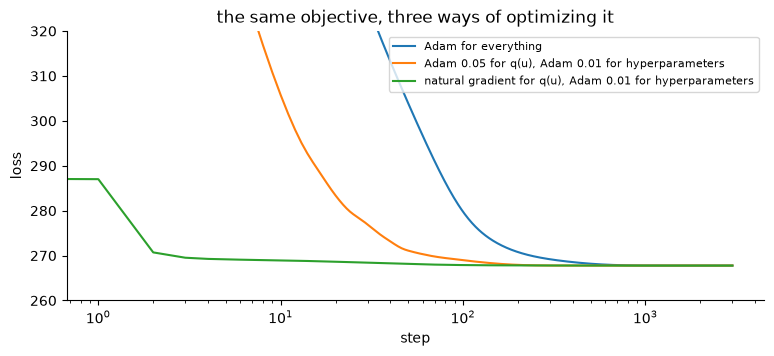

In [40]:
groups = {"q": ["f_q_mu", "f_q_sqrt"], "hyper": ["ls", "eta"]}
choices = {
    "Adam for everything": dict(optimizer=adam(1e-2)),
    "Adam 0.05 for q(u), Adam 0.01 for hyperparameters": dict(
        optimizer={"q": adam(5e-2, namespace="q"), "hyper": adam(1e-2, namespace="hyper")}, param_groups=groups),
    "natural gradient for q(u), Adam 0.01 for hyperparameters": dict(
        optimizer={"q": gpm.natural_gradient(0.5), "hyper": adam(1e-2)}, param_groups=groups),
}
fig, ax = plt.subplots(figsize=(9, 3.5))
for label, kw in choices.items():
    train_step, fit_o = gpm.compile_training_step(obj_o, **kw)
    losses = [train_step() for _ in range(3000)]
    print(f"{label:58s} loss after 50 steps {losses[49]:8.3f} | 500 steps {losses[499]:8.3f} | 3000 steps {losses[-1]:8.3f}")
    ax.plot(losses, label=label)
ax.set(xscale="log", ylim=(260, 320), xlabel="step", ylabel="loss", title="the same objective, three ways of optimizing it")
ax.legend(fontsize=8);

All three end at the same loss to two decimals (267.77 to 267.79). The natural gradient is within 0.4 of it after
50 steps, where Adam on everything is still 37 above it and needs a few thousand steps to close the gap, because it
has to learn the shape of $q(u)$ one coordinate at a time. Giving $q(u)$ its own, larger Adam rate sits in between.

**A check: with a Normal likelihood, one step is enough.** When the likelihood is Normal, the best $q(u)$ is known in
closed form, and it's what `VFE` uses. One natural-gradient step with $\gamma = 1$ lands exactly on it. Below, the
hyperparameters are held where they start (a plain gradient rule with rate 0), and one step of `SVGP` gives the loss
that `VFE` has at the same hyperparameters:

In [41]:
m_n = counts_model(normal=True)
obj_n = gpm.objective(m_n, {"f": gpm.SVGP(Z_o)})
train_step, fit_n = gpm.compile_training_step(
    obj_n,
    optimizer={"q": gpm.natural_gradient(1.0), "hyper": sgd(0.0)},
    param_groups={"q": ["f_q_mu", "f_q_sqrt"], "hyper": ["ls", "eta", "sigma"]},
)
print(f"SVGP loss at the start:           {train_step():.6f}")
print(f"SVGP loss after one natural step: {train_step():.6f}")
obj_v = gpm.objective(m_n, {"f": gpm.VFE(Z_o, train_Z=False)})
print(f"VFE loss, same hyperparameters:   {obj_v.function([obj_v.loss])(m_n.initial_point())[0]:.6f}")

SVGP loss at the start:           365.910125
SVGP loss after one natural step: 215.585857
VFE loss, same hyperparameters:   215.585857


(`train_step` returns the loss *before* its update, so the second call shows the effect of the first step.)

**When to use it.** Natural gradients pay off when $q(u)$ is the slow part: a non-Normal likelihood, fitted on all of
the data or on large batches. They cost an extra inverse and Cholesky factorization of each $M \times M$ covariance
per step, and a step that's too large for a non-Normal likelihood can make the covariance invalid, so $\gamma$ has to
be chosen (0.5 here; smaller on minibatches). On the water-main model of section 11 they made no difference: tried
outside this notebook, a natural gradient on the three GPs' $q(u)$ with Adam on the rest did no better than
Adam alone after the same number of steps, and took longer to compile. For a Normal likelihood on all of the data, use `VFE`, which is the one-step
answer above without the step.

## 16. Summary

**The model layer** is PyMC:

| You write | It is |
|---|---|
| `f = gpm.GP("f", kernel, mean)` | the GP itself, a process; not a variable |
| `f(X)` | the GP's values at the rows of `X`, a random variable named `f(X)`. All evaluations of `f` are one draw of the GP |
| `f_a(X) + f_b(X)` in a likelihood | a sum of GPs. It can be fitted as one GP: the sum is recognized from the GP nodes in the graph |
| any PyMC distribution, with `observed=` | a likelihood; any parameter can depend on any number of GPs |
| the same distribution, without `observed=` | a new observation to predict, such as `y_new`, with its link, exposure, effects and noise |
| (nothing) | which evaluations are observed: read from which ones the likelihoods use |
| `pm.Data`, `pm.Minibatch`, `total_size=` | where the data comes from, and how a batch is scaled |

**The objective layer** reads the model:

| Family | For | Terms |
|---|---|---|
| `Exact()` | a GP observed once, through a Normal likelihood whose mean is the GP | `mll[y]` |
| `VFE(Z)`, `FITC(Z)` | the same, sparse | `collapsed_elbo[y]`, `fitc[y]` |
| `SVGP(Z)` | a GP with any likelihoods, observed any number of times, minibatches | `kl[f]`, its part of each `expected_loglik[...]` |
| any of these, keyed by a tuple of GPs: `{("f_a", "f_b"): Exact()}` | GPs that a likelihood adds together (each times a scalar at most), fitted as one GP with the summed kernel | the same terms, once for the sum: `mll[y]`, or `kl[f_a+f_b]` |
| `MeanField()` | a variable with a Normal prior (random effects) | `kl[...]`, its part of `expected_loglik[y]` |
| `Gaussian(draws=S)` | a group of variables, with S fixed draws | `logp[...]` averaged over the draws, `entropy[...]` |
| `Point()` (default) | anything else | `logp[...]` |
| `penalties={...}` | extra loss terms | `penalty[...]`, outside `obj.bound` |

and returns an `Objective` with `terms`, `pointwise`, `diagnostics`, `bound`, `loss`, `params` (the variational
parameters) and `inputs` (the point-estimated model values). Families are keyed by the GP's name (`"f"`), not by an
evaluation. `Z` is an array of inducing inputs or a ptgp inducing-variable object. A new approximation is a new family
class; `objective` itself doesn't change.

**Fitting** gives a `Fit`, through one of two entry points shaped like ptgp's:

| | |
|---|---|
| `gpm.fit(obj)` | scipy's L-BFGS-B on the whole objective, like `ptgp.fit` |
| `train_step, fit = gpm.compile_training_step(obj, optimizer, param_groups)` | one step of a pytensor-ml optimizer; you write the loop. `optimizer` is one transform, or a dict of them with `param_groups` |
| `gpm.natural_gradient(gamma)` | a transform for the $q(u)$ of an `SVGP`, used as one group's optimizer |

The `Fit` holds `estimates`, `params`, `trace` (every term, every step), and `history` / `diagnostics` (ptgp's
diagnostics namedtuples).

**Prediction:**

| You want | Use |
|---|---|
| the GP's value at some inputs (a curve, a surface) | `fit.predict("f", X)`: an array in, mean and variance out; nothing in the model |
| GPs fitted as a sum | `fit.predict("f_a", X)` for one of them, `fit.predict("f_a+f_b", X)` for the sum |
| a new observation | a variable like `y_new` in the model, and `fit.predict_new("y_new")`; move it with `pm.set_data`, setting all its inputs together |
| how well held-out data is predicted | `fit.log_predictive("y_new", y_test)` |

The fit records its training data, and prediction refuses if it has changed since.

**Limits of this prototype:**

- the linear predictor's variance assumes each row reads one element of each latent (section 2.3); that isn't checked;
- without a linear predictor, the expected log-likelihood is a grid over the GP values, which grows exponentially with
  the number of GPs;
- ptgp's runtime domain check for Fourier features isn't wired into `compile_training_step`;
- GPs whose inputs are other latents (deep GPs) can be written as a model, but no family fits them;
- the conditional of a later evaluation adds its own jitter, so the joint density of two evaluations differs from
  the exact joint by a small amount (about 1e-4 in log density in a 9-point check).